# Gold layer — Steps 10, 11, 12, 13

> **Development notebook.** The Gold layer is built and explained here. Once final, it is converted to the callable module `util/dataprocessing_gold.py`. Change this notebook first, then re-convert.

| Step | Section | Output (`datamart/gold/`) |
|---|---|---|
| 10 | Join and aggregate | Model-grain feature table (one row per loan, as of `loan_start_date`), `_reports/join_diagnostics.csv` |
| 11 | Feature store | `feature_store/v1/` (versioned), `feature_dictionary.csv`, historical-replay test |
| 12 | Label store | `label_store/30dpd_6mob/`, `_reports/label_summary.csv` |
| 13 | Reconciliation | `_reports/gold_acceptance_report.csv` — the stores are written to staging and **only promoted if every check passes** |

**Decisions agreed for this layer**

| # | Decision |
|---|---|
| 1 | Grain: **one row per loan** (`loan_id`), scored at `loan_start_date`; `Customer_ID` kept as identifier (never a feature) |
| 2 | Clickstream: **latest snapshot ≤ loan start** (history aggregates would be step 20) |
| 3 | Feature store: **versioned Parquet folders** (`v1`, `v2`, …) + feature dictionary (records the version each feature was added) |
| 4 | **Separate feature and label stores**, joined only in the ML pipeline (no label can sit next to the features) |
| 5 | `Type_of_Loan` list → **9 loan-type flags** (`has_payday_loan`, …) + `num_loan_types` |
| 6 | Contract v1.1.0: **derived features declared**; raw text (`Type_of_Loan`, `Credit_History_Age`) replaced by the parsed versions |
| 7 | Label store: label, `label_def`, outcome date, DPD at MOB 6, **maturity status** (mature / immature / censored) |
| 8 | Partitions: feature store by `loan_start_date` (scoring month); label store by `label_snapshot_date` (MOB-6 month) |
| 9 | **No `has_clickstream` flag** — coverage is a time break (100% of loans starting ≤ 2024-06, 0% after), so a flag would be a date proxy; clickstream stays null where unavailable and the coverage break is documented in the dictionary |

In [1]:
import os, sys, re, shutil, uuid
from datetime import datetime, timezone

import numpy as np
import pandas as pd
import yaml
from pyspark.sql import Window, functions as F, types as T

# Project folder: /app inside the Docker container, otherwise the parent of this notebook's folder
PROJECT_DIR = os.environ.get("PROJECT_DIR") or ("/app" if os.path.isdir("/app/data") else os.path.abspath(".."))
sys.path.insert(0, PROJECT_DIR)
from util import dataprocessing_bronze as bronze      # Spark session, source headers
from util import dataprocessing_silver as silver      # Silver reader

GOLD_DIR          = os.path.join(PROJECT_DIR, "datamart", "gold")
FEATURE_STORE_DIR = os.path.join(GOLD_DIR, "feature_store")
LABEL_STORE_DIR   = os.path.join(GOLD_DIR, "label_store")
REPORT_DIR        = os.path.join(GOLD_DIR, "_reports")
CHART_DIR         = os.path.join(REPORT_DIR, "charts")
LOG_PATH          = os.path.join(GOLD_DIR, "_gold_log.csv")
DICTIONARY_PATH   = os.path.join(GOLD_DIR, "feature_dictionary.csv")
for d in (GOLD_DIR, FEATURE_STORE_DIR, LABEL_STORE_DIR, REPORT_DIR, CHART_DIR):
    os.makedirs(d, exist_ok=True)

with open(os.path.join(PROJECT_DIR, "config", "data_contract.yaml"), encoding="utf-8") as f:
    CONTRACT = yaml.safe_load(f)

spark = bronze.get_spark("gold")

## Configuration (from the data contract)

In [2]:
TARGET       = CONTRACT["target"]
LABEL_DEF    = TARGET["label_def"]            # 30dpd_6mob
MOB          = TARGET["mob"]                  # 6
DPD_THRESHOLD = TARGET["dpd_threshold"]       # 30
SCORING_COL  = CONTRACT["scoring_timestamp"]["column"]   # loan_start_date
LABEL_TABLE  = TARGET["table"]                # lms_loan_daily
FEATURE_TABLES = [t for t, r in CONTRACT["feature_availability"]["tables"].items() if r["allowed"]]

FEATURE_VERSION = "v1"
SHORT = {"features_attributes": "attributes", "features_financials": "financials", "feature_clickstream": "clickstream"}

# Unmatched-join tolerance (% of loans with no feature row at scoring time)
UNMATCHED_TOLERANCE = {"features_attributes": 0.0, "features_financials": 0.0,
                       "feature_clickstream": 30.0}   # accepted coverage break (BRZ-001): 28.2% expected

EXCLUDED = (set(CONTRACT["excluded_columns"]["identifiers"])
            | {c for cols in CONTRACT["excluded_columns"]["pii"].values() for c in cols}
            | {c for cols in CONTRACT["excluded_columns"].get("replaced_by_derived", {}).values() for c in cols})

KNOWN_LOAN_TYPES = silver.KNOWN_LOAN_TYPES
def loan_type_column(loan_type):
    slug = re.sub(r"[^a-z0-9]+", "_", loan_type.lower()).strip("_")
    return f"has_{slug}" if slug.endswith("loan") else f"has_{slug}_loan"
LOAN_TYPE_COLUMNS = {loan_type_column(t): t for t in KNOWN_LOAN_TYPES}

print("Label:", LABEL_DEF, "| scoring timestamp:", SCORING_COL, "| feature tables:", FEATURE_TABLES)
print("Loan-type flags:", list(LOAN_TYPE_COLUMNS))

Label: 30dpd_6mob | scoring timestamp: loan_start_date | feature tables: ['features_attributes', 'features_financials', 'feature_clickstream']
Loan-type flags: ['has_auto_loan', 'has_credit_builder_loan', 'has_debt_consolidation_loan', 'has_home_equity_loan', 'has_mortgage_loan', 'has_not_specified_loan', 'has_payday_loan', 'has_personal_loan', 'has_student_loan']


## Contract predictor check

The same rule as the step-01 contract tests: a column may be a predictor only if it is an allowed source column or a declared derived feature of an allowed feature table — never a label-source column, PII, identifier or replaced raw text.

In [3]:
def allowed_predictors():
    out = {}
    for t, rule in CONTRACT["feature_availability"]["tables"].items():
        if not rule["allowed"]:
            continue
        src = CONTRACT["sources"][t]
        header = bronze.source_profile(os.path.join(bronze.RAW_DIR, src["file"]))[0]
        for c in header:
            if c not in EXCLUDED and c not in src["keys"] and c != src["event_time"]:
                out[c] = t
        for c in CONTRACT.get("derived_features", {}).get(t, {}):
            out[c] = t
    return out


def check_predictors(columns):
    allowed = allowed_predictors()
    rejected = [c for c in columns if c not in allowed]
    if rejected:
        raise ValueError(f"Predictors rejected by the data contract: {rejected}")
    return True

print(f"{len(allowed_predictors())} predictors allowed by contract v{CONTRACT['contract']['version']}")

68 predictors allowed by contract v1.1.0


---

## Step 10 — Join and aggregate

**Spine:** one row per loan from Silver `lms_loan_daily` (`loan_id`, `Customer_ID`, `loan_start_date`).

**As-of joins** (contract rule): for each feature table, join on `Customer_ID` and keep the **latest snapshot with `snapshot_date <= loan_start_date`**. Rows dated after the scoring timestamp ("late arrivals") are excluded and counted. The snapshot date used is kept as `_asof_<source>` metadata (not a predictor) for the point-in-time check in step 13.

**Diagnostics per join:** candidate rows, future rows excluded, matched / unmatched %, rows per loan before and after picking (row explosion), snapshot lag in months, and the assertion that the output has exactly one row per loan.

In [4]:
def feature_columns(table, df):
    src = CONTRACT["sources"][table]
    return [c for c in df.columns
            if not c.startswith("_") and c not in EXCLUDED and c not in src["keys"]
            and c != src["event_time"] and c != "type_of_loan_list"]


def build_spine(lms):
    return lms.select("loan_id", "Customer_ID", SCORING_COL).distinct()


def asof_join(spine, feat, table, cols):
    short = SHORT[table]
    f = feat.select(F.col("Customer_ID").alias("_cust"), F.col("snapshot_date").alias("_snap"), *cols)
    cand = spine.join(f, spine["Customer_ID"] == f["_cust"], "left")
    valid = cand.filter(F.col("_snap").isNull() | (F.col("_snap") <= F.col(SCORING_COL)))
    w = Window.partitionBy("loan_id").orderBy(F.col("_snap").desc_nulls_last())
    picked = (valid.withColumn("_rn", F.row_number().over(w)).filter("_rn = 1")
                   .select("loan_id", F.col("_snap").alias(f"_asof_{short}"), *cols))
    out = spine.join(picked, "loan_id", "left")      # loans whose rows were all in the future come back as null

    diag = cand.agg(
        F.sum(F.col("_snap").isNotNull().cast("int")).alias("candidate_rows"),
        F.sum((F.col("_snap") > F.col(SCORING_COL)).cast("int")).alias("future_rows_excluded")).first().asDict()
    per_loan = cand.groupBy("loan_id").count().agg(F.max("count")).first()[0]
    stats = out.agg(F.count("*").alias("output_rows"), F.countDistinct("loan_id").alias("loans"),
                    F.sum(F.col(f"_asof_{short}").isNotNull().cast("int")).alias("matched")).first().asDict()
    lag = (out.filter(F.col(f"_asof_{short}").isNotNull())
              .select(F.months_between(SCORING_COL, f"_asof_{short}").cast("int").alias("lag"))
              .groupBy("lag").count().orderBy("lag").collect())
    n = stats["loans"]
    diag.update(table=table, spine_loans=spine.count(), max_rows_per_loan_before_pick=per_loan,
                output_rows=stats["output_rows"], matched_loans=stats["matched"],
                matched_pct=stats["matched"] / n * 100, unmatched_loans=n - stats["matched"],
                unmatched_pct=(n - stats["matched"]) / n * 100,
                snapshot_lag_months="; ".join(f"{r['lag']}m: {r['count']:,}" for r in lag))
    return out, diag


def add_loan_type_flags(df):
    for col, loan_type in LOAN_TYPE_COLUMNS.items():
        df = df.withColumn(col, F.coalesce(F.array_contains("type_of_loan_list", loan_type), F.lit(False)).cast("int"))
    return df.drop("type_of_loan_list")


def build_features(spine, frames):
    # Model-grain feature table: spine + as-of joins of every allowed feature table + Gold-derived loan-type flags
    out, diagnostics = spine, []
    for t in FEATURE_TABLES:
        cols = feature_columns(t, frames[t]) + (["type_of_loan_list"] if t == "features_financials" else [])
        joined, diag = asof_join(spine, frames[t], t, cols)
        out = out.join(joined.drop("Customer_ID", SCORING_COL), "loan_id", "left")
        diagnostics.append(diag)
    return add_loan_type_flags(out), diagnostics

### Step 10 tests — future exclusion and join cardinality

In [5]:
sp = spark.createDataFrame([("L1", "C1", "2024-03-01"), ("L2", "C2", "2024-03-01"), ("L3", "C3", "2024-03-01")],
                           "loan_id string, Customer_ID string, loan_start_date string") \
          .withColumn("loan_start_date", F.to_date("loan_start_date"))
ft = spark.createDataFrame([("C1", "2024-01-01", "past"), ("C1", "2024-03-01", "same_day"), ("C1", "2024-04-01", "FUTURE"),
                            ("C2", "2024-05-01", "FUTURE")],
                           "Customer_ID string, snapshot_date string, x string") \
          .withColumn("snapshot_date", F.to_date("snapshot_date"))
res, d = asof_join(sp, ft, "feature_clickstream", ["x"])
got = {r["loan_id"]: r["x"] for r in res.collect()}
assert got == {"L1": "same_day", "L2": None, "L3": None}, got        # latest <= scoring date; never a future row
assert d["output_rows"] == 3 and d["future_rows_excluded"] == 2 and d["matched_loans"] == 1, d
print("Step 10 tests passed: latest snapshot on or before the scoring date is picked, future-dated rows are never "
      "used, loans with only future rows stay null, one output row per loan")

Step 10 tests passed: latest snapshot on or before the scoring date is picked, future-dated rows are never used, loans with only future rows stay null, one output row per loan


### Run step 10

In [6]:
frames = {t: silver.read_silver(spark, t) for t in [LABEL_TABLE] + FEATURE_TABLES}
spine = build_spine(frames[LABEL_TABLE]).cache()
assert spine.count() == spine.select("loan_id").distinct().count(), "spine has more than one row per loan"

features, diagnostics = build_features(spine, frames)
features = features.cache()
join_diagnostics = pd.DataFrame(diagnostics)[[
    "table", "spine_loans", "candidate_rows", "future_rows_excluded", "max_rows_per_loan_before_pick", "output_rows",
    "matched_loans", "matched_pct", "unmatched_loans", "unmatched_pct", "snapshot_lag_months"]]
join_diagnostics.to_csv(os.path.join(REPORT_DIR, "join_diagnostics.csv"), index=False)

FEATURES = [c for c in features.columns if c not in ("loan_id", "Customer_ID", SCORING_COL) and not c.startswith("_")]
check_predictors(FEATURES)
assert features.count() == spine.count() == features.select("loan_id").distinct().count(), "row explosion or loss"
print(f"Model-grain table: {features.count():,} loans x {len(FEATURES)} features (all allowed by the contract)")
join_diagnostics.style.hide(axis="index").format(
    {"spine_loans": "{:,}", "candidate_rows": "{:,}", "future_rows_excluded": "{:,}", "output_rows": "{:,}",
     "matched_loans": "{:,}", "unmatched_loans": "{:,}", "matched_pct": "{:.1f}%", "unmatched_pct": "{:.1f}%"})

Model-grain table: 12,500 loans x 68 features (all allowed by the contract)


table,spine_loans,candidate_rows,future_rows_excluded,max_rows_per_loan_before_pick,output_rows,matched_loans,matched_pct,unmatched_loans,unmatched_pct,snapshot_lag_months
features_attributes,"12,500","12,500",0,1,"12,500","12,500",100.0%,0,0.0%,"0m: 12,500"
features_financials,"12,500","12,500",0,1,"12,500","12,500",100.0%,0,0.0%,"0m: 12,500"
feature_clickstream,"12,500","215,376","130,468",24,"12,500","8,974",71.8%,"3,526",28.2%,"0m: 8,974"


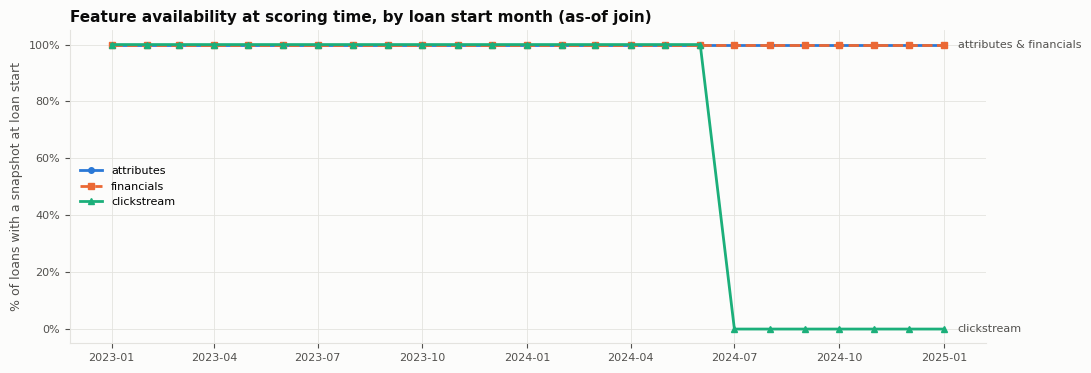

In [7]:
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker

SURFACE, INK, INK_2, GRID = "#fcfcfb", "#0b0b0b", "#52514e", "#e4e3df"
SERIES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": GRID, "axes.labelcolor": INK_2, "axes.titlecolor": INK, "axes.titlesize": 11,
    "axes.titleweight": "bold", "axes.titlelocation": "left", "xtick.color": INK_2, "ytick.color": INK_2,
    "xtick.labelsize": 8, "ytick.labelsize": 8, "axes.grid": True, "axes.axisbelow": True, "grid.color": GRID,
    "grid.linewidth": 0.6, "axes.spines.top": False, "axes.spines.right": False, "legend.frameon": False,
    "legend.fontsize": 8, "font.size": 9, "lines.linewidth": 2})

# Feature availability at scoring time, by loan cohort
cov = (features.groupBy(SCORING_COL)
       .agg(*[F.avg(F.col(f"_asof_{SHORT[t]}").isNotNull().cast("double")).alias(SHORT[t]) for t in FEATURE_TABLES])
       .orderBy(SCORING_COL).toPandas())
cov[SCORING_COL] = pd.to_datetime(cov[SCORING_COL])
fig, ax = plt.subplots(figsize=(11, 3.8))
markers = {"attributes": "o", "financials": "s", "clickstream": "^"}
for color, t in zip(SERIES, FEATURE_TABLES):
    s = SHORT[t]
    ax.plot(cov[SCORING_COL], cov[s] * 100, color=color, marker=markers[s], markersize=4, label=s,
            linestyle="--" if s == "financials" else "-")
# end labels: lines at the same level share one label
ends = cov.iloc[-1]
for level in sorted({round(ends[SHORT[t]] * 100) for t in FEATURE_TABLES}):
    names = [SHORT[t] for t in FEATURE_TABLES if round(ends[SHORT[t]] * 100) == level]
    ax.text(cov[SCORING_COL].iloc[-1] + pd.Timedelta(days=12), level, " & ".join(names), va="center", fontsize=8, color=INK_2)
ax.set_ylim(-5, 105)
ax.yaxis.set_major_formatter(mticker.PercentFormatter(decimals=0))
ax.set_ylabel("% of loans with a snapshot at loan start")
ax.legend(loc="center left")
ax.set_title("Feature availability at scoring time, by loan start month (as-of join)")
fig.tight_layout()
fig.savefig(os.path.join(CHART_DIR, "10_1_feature_availability_by_cohort.png"), dpi=130, bbox_inches="tight")
plt.show()

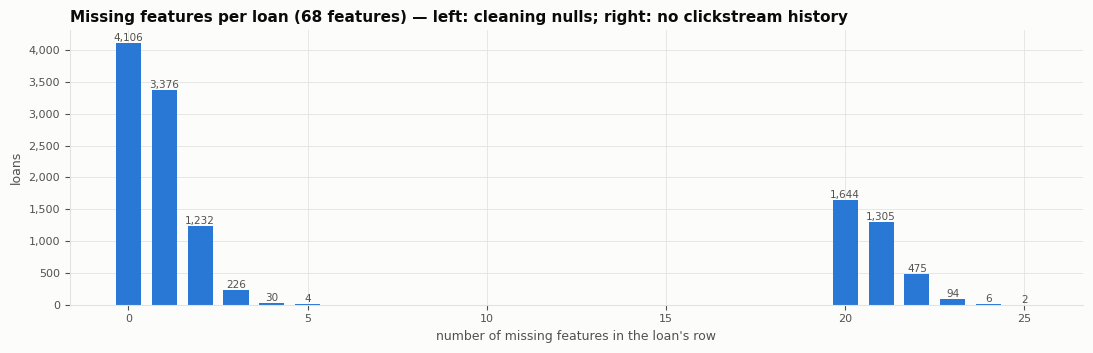

Loans with every feature filled: 32.8%


In [8]:
# Missing features per loan: two clusters — cleaning nulls (0-5) vs no clickstream history (20+)
pdf = features.select(*FEATURES).toPandas()
missing = pdf.isna().sum(axis=1).value_counts().sort_index()
fig, ax = plt.subplots(figsize=(11, 3.6))
ax.bar(missing.index, missing.values, color=SERIES[0], width=0.7)
for x, v in missing.items():
    ax.text(x, v, f"{v:,}", ha="center", va="bottom", fontsize=7.5, color=INK_2)
ax.set_xlabel("number of missing features in the loan's row")
ax.set_ylabel("loans")
ax.yaxis.set_major_formatter(mticker.StrMethodFormatter("{x:,.0f}"))
ax.set_title(f"Missing features per loan ({len(FEATURES)} features) — left: cleaning nulls; right: no clickstream history")
fig.tight_layout()
fig.savefig(os.path.join(CHART_DIR, "10_2_missing_features_per_loan.png"), dpi=130, bbox_inches="tight")
plt.show()
print(f"Loans with every feature filled: {(pdf.isna().sum(axis=1) == 0).mean() * 100:.1f}%")

---

## Step 11 — Feature store (versioned tables + dictionary)

- **Store:** `feature_store/v1/` partitioned by `loan_start_date`; one row per loan; keys `loan_id`, `Customer_ID`, `loan_start_date`; `_asof_*` snapshot dates and `_feature_version` as metadata.
- **Dictionary:** every feature with type, unit, source table and columns, derivation, as-of rule, freshness, owner, version added, null % and coverage notes.
- **As-of retrieval:** `get_features(as_of=...)` returns the features for loans scored on or before a date.
- **Historical replay test:** for three loan cohorts, the features are rebuilt from Silver **truncated to that cohort's scoring date** (as if run on that day) and must equal the stored rows — proving no later data leaked in.

In [9]:
UNITS = {
    "Age": "years", "Annual_Income": "currency per year", "Monthly_Inhand_Salary": "currency per month",
    "Num_Bank_Accounts": "count", "Num_Credit_Card": "count", "Interest_Rate": "percent", "Num_of_Loan": "count",
    "Delay_from_due_date": "days", "Num_of_Delayed_Payment": "count",
    "Changed_Credit_Limit": "change in credit limit (unit not documented in source)",
    "Num_Credit_Inquiries": "count", "Outstanding_Debt": "currency", "Credit_Utilization_Ratio": "percent",
    "Total_EMI_per_month": "currency per month", "Amount_invested_monthly": "currency per month",
    "Monthly_Balance": "currency", "credit_history_age_months": "months", "num_loan_types": "count",
}


def describe_feature(col, dtype):
    table = allowed_predictors()[col]
    derived = CONTRACT.get("derived_features", {}).get(table, {}).get(col)
    if col in LOAN_TYPE_COLUMNS:
        derivation, layer = f"1 if '{LOAN_TYPE_COLUMNS[col]}' is in the parsed loan list, else 0", "gold (step 10)"
    elif derived:
        derivation, layer = derived["rule"], "silver (step 07/09)"
    else:
        derivation, layer = "source column (cleaned in Silver)", "silver (step 07)"
    if col.endswith("_invalid") or col in LOAN_TYPE_COLUMNS or col == "type_of_loan_unknown":
        unit = "flag (0/1)"
    elif dtype == "string":
        unit = "category"
    elif col.startswith("fe_"):
        unit = "clickstream score (unitless)"
    else:
        unit = UNITS.get(col, "")
    note = ""
    if table == "feature_clickstream":
        note = ("coverage break by time: available for loans starting 2023-01..2024-06 (100%), "
                "none for loans starting 2024-07 onwards; null = no clickstream history")
    return dict(feature=col, version_added=FEATURE_VERSION, dtype=dtype, unit=unit, source_table=table,
                source_columns=", ".join(derived["from"]) if derived else (col if col not in LOAN_TYPE_COLUMNS else "Type_of_Loan"),
                derivation=derivation, built_in=layer,
                as_of_rule=CONTRACT["feature_availability"]["tables"][table]["as_of"],
                freshness="monthly snapshot; latest snapshot on or before loan_start_date",
                entity_key="loan_id (via Customer_ID as-of join)", owner=CONTRACT["contract"]["owner"],
                allowed_by_contract=True, coverage_note=note)


dtypes = dict(features.dtypes)
dictionary = pd.DataFrame([describe_feature(c, dtypes[c]) for c in FEATURES])
null_pct = features.select([F.avg(F.col(c).isNull().cast("double")).alias(c) for c in FEATURES]).first().asDict()
dictionary["null_pct"] = dictionary["feature"].map(lambda c: round(null_pct[c] * 100, 2))
dictionary.to_csv(DICTIONARY_PATH, index=False)
print(f"Feature dictionary: {len(dictionary)} features "
      f"({dictionary['built_in'].value_counts().to_dict()})")
dictionary[["feature", "dtype", "unit", "source_table", "derivation", "null_pct", "coverage_note"]].style.hide(axis="index")

Feature dictionary: 68 features ({'silver (step 07)': 40, 'silver (step 07/09)': 19, 'gold (step 10)': 9})


feature,dtype,unit,source_table,derivation,null_pct,coverage_note
Age,int,years,features_attributes,source column (cleaned in Silver),2.550000,
Age_invalid,boolean,flag (0/1),features_attributes,source value invalid / out of range,0.000000,
Occupation,string,category,features_attributes,source column (cleaned in Silver),7.040000,
Occupation_invalid,boolean,flag (0/1),features_attributes,placeholder category,0.000000,
Annual_Income,double,currency per year,features_financials,source column (cleaned in Silver),0.880000,
Annual_Income_invalid,boolean,flag (0/1),features_financials,source value invalid / out of range (set to null in Silver),0.000000,
Monthly_Inhand_Salary,double,currency per month,features_financials,source column (cleaned in Silver),0.000000,
Num_Bank_Accounts,int,count,features_financials,source column (cleaned in Silver),1.340000,
Num_Bank_Accounts_invalid,boolean,flag (0/1),features_financials,source value invalid / out of range,0.000000,
Num_Credit_Card,int,count,features_financials,source column (cleaned in Silver),2.310000,


In [10]:
def staging_path(final):
    return final + "__staging"


def write_staged(df, final, partition_col):
    silver.write_parquet_atomic(df, staging_path(final), partition_col)


def promote(final):
    shutil.rmtree(final, ignore_errors=True)
    os.replace(staging_path(final), final)


def get_features(as_of=None, version=FEATURE_VERSION, staged=False):
    # As-of retrieval: features of loans scored on or before `as_of`
    path = os.path.join(FEATURE_STORE_DIR, version)
    df = spark.read.parquet(staging_path(path) if staged else path)
    return df if as_of is None else df.filter(F.col(SCORING_COL) <= F.lit(as_of).cast("date"))


GOLD_BATCH = f"gold_{datetime.now(timezone.utc):%Y%m%dT%H%M%SZ}_{uuid.uuid4().hex[:6]}"
GOLD_TS = datetime.now(timezone.utc).strftime("%Y-%m-%dT%H:%M:%SZ")
FEATURE_STORE_PATH = os.path.join(FEATURE_STORE_DIR, FEATURE_VERSION)

feature_store = (features.withColumn("_feature_version", F.lit(FEATURE_VERSION))
                         .withColumn("_gold_batch_id", F.lit(GOLD_BATCH)).withColumn("_gold_ts", F.lit(GOLD_TS)))
write_staged(feature_store, FEATURE_STORE_PATH, SCORING_COL)
print("Feature store staged:", staging_path(FEATURE_STORE_PATH))

Feature store staged: C:\Users\alber\Documents\Github\CS_611\Assignment 2\datamart\gold\feature_store\v1__staging


### Step 11 test — historical replay

In [11]:
cohorts = [r[0] for r in spine.select(SCORING_COL).distinct().orderBy(SCORING_COL).collect()]
replay_dates = [cohorts[0], cohorts[len(cohorts) // 2], cohorts[-1]]
compare_cols = ["loan_id", "Customer_ID", SCORING_COL] + FEATURES + [f"_asof_{SHORT[t]}" for t in FEATURE_TABLES]
stored = get_features(staged=True)

replay_rows = []
for d in replay_dates:
    truncated = {t: frames[t].filter(F.col("snapshot_date") <= F.lit(d)) for t in FEATURE_TABLES}
    sp_d = spine.filter(F.col(SCORING_COL) == F.lit(d))
    rebuilt, _ = build_features(sp_d, truncated)
    a = rebuilt.select(*compare_cols)
    b = stored.filter(F.col(SCORING_COL) == F.lit(d)).select(*compare_cols)
    diff = a.exceptAll(b).count() + b.exceptAll(a).count()
    replay_rows.append(dict(cohort=str(d), loans=sp_d.count(), differing_rows=diff))
    assert diff == 0, f"historical replay differs for cohort {d}"
print("Step 11 test passed: features rebuilt from Silver truncated to each cohort's scoring date equal the stored features")
pd.DataFrame(replay_rows).style.hide(axis="index")

Step 11 test passed: features rebuilt from Silver truncated to each cohort's scoring date equal the stored features


cohort,loans,differing_rows
2023-01-01,530,0
2024-01-01,485,0
2025-01-01,526,0


---

## Step 12 — Label store

Label definition from the contract (same convention as the course labs):

| Field | Rule |
|---|---|
| `mob` | `installment_num` |
| `installments_missed` | `ceil(overdue_amt / due_amt)`; 0 when nothing is overdue |
| `first_missed_date` | `snapshot_date − installments_missed months` |
| `dpd` | days from `first_missed_date` to `snapshot_date` (0 when nothing is overdue) |
| `label` | **1 if `dpd ≥ 30` on the snapshot where `mob = 6`**, else 0 |

**Maturity:** `mature` = the MOB-6 snapshot exists → labelled; `immature` = MOB 6 falls after the data cut-off → **no label** (never labelled 0); `censored` = MOB 6 is before the cut-off but the snapshot is missing → no label. Only mature labels may be used for training.

Prevalence is reported **overall only** — target rates by time or group are feature/target EDA, done on the training partition only (step 14).

In [12]:
def build_labels(lms, spine, cutoff):
    d = (lms.withColumn("mob", F.col("installment_num"))
            .withColumn("installments_missed",
                        F.when(F.col("overdue_amt") <= 0, F.lit(0))
                         .when(F.col("due_amt") > 0, F.ceil(F.col("overdue_amt") / F.col("due_amt"))).cast("int"))
            .withColumn("first_missed_date",
                        F.when(F.col("installments_missed") > 0,
                               F.add_months("snapshot_date", -F.col("installments_missed"))))
            .withColumn("dpd", F.when(F.col("overdue_amt") > 0, F.datediff("snapshot_date", "first_missed_date"))
                                .when(F.col("installments_missed") == 0, F.lit(0))))
    at_mob = (d.filter(F.col("mob") == MOB)
               .select("loan_id", F.col("snapshot_date").alias("label_snapshot_date"),
                       F.col("dpd").alias(f"dpd_at_mob{MOB}"), F.col("overdue_amt").alias(f"overdue_amt_at_mob{MOB}"),
                       F.col("installments_missed").alias(f"installments_missed_at_mob{MOB}")))
    expected = F.add_months(F.col(SCORING_COL), MOB)
    labels = (spine.join(at_mob, "loan_id", "left")
              .withColumn("expected_outcome_date", expected)
              .withColumn("maturity_status",
                          F.when(F.col("label_snapshot_date").isNotNull() & F.col(f"dpd_at_mob{MOB}").isNotNull(), "mature")
                           .when(expected > F.lit(cutoff), "immature")
                           .otherwise("censored"))
              .withColumn("label", F.when(F.col("maturity_status") == "mature",
                                          (F.col(f"dpd_at_mob{MOB}") >= DPD_THRESHOLD).cast("int")))
              .withColumn("label_def", F.lit(LABEL_DEF))
              .withColumn("data_cutoff", F.lit(cutoff)))
    return labels.select("loan_id", "Customer_ID", SCORING_COL, "label", "label_def", "maturity_status",
                         "label_snapshot_date", "expected_outcome_date", f"dpd_at_mob{MOB}",
                         f"overdue_amt_at_mob{MOB}", f"installments_missed_at_mob{MOB}", "data_cutoff")

### Step 12 tests — label rules on known ledgers

In [13]:
def ledger(loan, start, months, overdue_at):
    s = pd.Timestamp(start)
    return [(loan, f"C{loan}", s.date(), m, 0.0 if m == 0 else 1000.0, float(overdue_at.get(m, 0.0)),
             (s + pd.DateOffset(months=m)).date()) for m in months]

rows = (ledger("A", "2024-01-01", range(0, 11), {})                    # always paid -> dpd 0 -> label 0
        + ledger("B", "2024-01-01", range(0, 11), {6: 2000})          # 2 missed at MOB 6 -> dpd 61 -> label 1
        + ledger("C", "2023-09-01", range(0, 11), {6: 1000})          # 1 missed, MOB 6 = 2024-03: dpd 29 (Feb) -> 0
        + ledger("D", "2025-09-01", range(0, 3), {})                  # MOB 6 after cut-off -> immature, no label
        + ledger("E", "2024-01-01", range(0, 5), {}))                 # MOB 6 before cut-off but missing -> censored
schema = "loan_id string, Customer_ID string, loan_start_date date, installment_num int, due_amt double, overdue_amt double, snapshot_date date"
test_lms = spark.createDataFrame(rows, schema)
test_labels = {r["loan_id"]: r for r in build_labels(test_lms, build_spine(test_lms), pd.Timestamp("2025-11-01").date()).collect()}

assert (test_labels["A"]["label"], test_labels["A"]["dpd_at_mob6"]) == (0, 0)
assert (test_labels["B"]["label"], test_labels["B"]["dpd_at_mob6"]) == (1, 61)
assert (test_labels["C"]["label"], test_labels["C"]["dpd_at_mob6"]) == (0, 29)   # lab convention: calendar days
assert test_labels["D"]["maturity_status"] == "immature" and test_labels["D"]["label"] is None
assert test_labels["E"]["maturity_status"] == "censored" and test_labels["E"]["label"] is None
print("Step 12 tests passed: on-time -> 0, 2 missed -> 1, immature and censored loans get no label (never 0). "
      "Documented edge case: 1 missed instalment over February gives dpd 29 -> 0 under the calendar-day convention "
      "(no such loan exists in this data: the minimum at MOB 6 is 2 missed)")

Step 12 tests passed: on-time -> 0, 2 missed -> 1, immature and censored loans get no label (never 0). Documented edge case: 1 missed instalment over February gives dpd 29 -> 0 under the calendar-day convention (no such loan exists in this data: the minimum at MOB 6 is 2 missed)


### Run step 12

In [14]:
cutoff = frames[LABEL_TABLE].agg(F.max("snapshot_date")).first()[0]
labels = build_labels(frames[LABEL_TABLE], spine, cutoff).cache()

label_summary = (labels.groupBy("maturity_status")
                 .agg(F.count("*").alias("loans"), F.sum("label").alias("label_1"),
                      F.avg("label").alias("label_rate")).toPandas())
label_summary["label_rate_pct"] = label_summary["label_rate"] * 100
label_summary = label_summary.drop(columns="label_rate")
label_summary.insert(0, "label_def", LABEL_DEF)
label_summary["data_cutoff"] = str(cutoff)
label_summary.to_csv(os.path.join(REPORT_DIR, "label_summary.csv"), index=False)

missed = labels.groupBy(f"installments_missed_at_mob{MOB}").count().orderBy(f"installments_missed_at_mob{MOB}").toPandas()

LABEL_STORE_PATH = os.path.join(LABEL_STORE_DIR, LABEL_DEF)
label_store = labels.withColumn("_gold_batch_id", F.lit(GOLD_BATCH)).withColumn("_gold_ts", F.lit(GOLD_TS))
write_staged(label_store, LABEL_STORE_PATH, "label_snapshot_date")
print("Label store staged:", staging_path(LABEL_STORE_PATH), "| data cut-off:", cutoff)
display(label_summary.style.hide(axis="index").format({"loans": "{:,}", "label_1": "{:,.0f}", "label_rate_pct": "{:.2f}%"}))
missed.style.hide(axis="index").format({"count": "{:,}"})

Label store staged: C:\Users\alber\Documents\Github\CS_611\Assignment 2\datamart\gold\label_store\30dpd_6mob__staging | data cut-off: 2025-11-01


label_def,maturity_status,loans,label_1,label_rate_pct,data_cutoff
30dpd_6mob,mature,"12,500","3,602",28.82%,2025-11-01


installments_missed_at_mob6,count
0,"8,898"
2,681
3,"1,133"
4,"1,115"
5,541
6,132


---

## Step 13 — Gold reconciliation (acceptance report)

Run on the **staged** stores. **Release is blocked** (nothing promoted) if any check fails — in particular key duplication or leakage.

| # | Check |
|---|---|
| 1–3 | Feature store and label store: one row per loan, no null keys |
| 4 | Same loan population in Silver, feature store and label store |
| 5 | Features ⋈ mature labels is 1:1 with no loss |
| 6 | Unmatched joins within tolerance (attributes/financials 0%; clickstream ≤ 30%, documented coverage break) |
| 7 | Only mature loans carry a label; immature / censored loans have none |
| 8 | Point-in-time: every feature snapshot date ≤ `loan_start_date` |
| 9 | Outcome after scoring: label snapshot = `loan_start_date` + 6 months |
| 10 | No label in X: no label or label-source column in the feature store |
| 11 | Every predictor allowed by the data contract |
| 12 | Feature dictionary documents exactly the stored features |

In [15]:
fs = get_features(staged=True)
ls = spark.read.parquet(staging_path(LABEL_STORE_PATH))
results = []

def check(name, ok, observed, rule):
    results.append(dict(check=name, status="PASS" if ok else "FAIL", observed=observed, rule=rule))

def dup_and_null(df, name):
    dups = df.groupBy("loan_id").count().filter("count > 1").count()
    nulls = df.filter(F.col("loan_id").isNull() | F.col("Customer_ID").isNull() | F.col(SCORING_COL).isNull()).count()
    check(f"{name}: one row per loan", dups == 0, f"{dups} duplicate loan_id", "0 duplicates")
    check(f"{name}: no null keys", nulls == 0, f"{nulls} rows with a null key", "0")

dup_and_null(fs, "feature store")
dup_and_null(ls, "label store")

silver_loans = {r[0] for r in frames[LABEL_TABLE].select("loan_id").distinct().collect()}
fs_loans = {r[0] for r in fs.select("loan_id").collect()}
ls_loans = {r[0] for r in ls.select("loan_id").collect()}
check("same loan population (Silver = feature store = label store)", silver_loans == fs_loans == ls_loans,
      f"Silver {len(silver_loans):,} / features {len(fs_loans):,} / labels {len(ls_loans):,}", "identical sets")

mature = ls.filter(F.col("maturity_status") == "mature")
joined = fs.join(mature.select("loan_id", "label"), "loan_id", "inner")
n_mature, n_joined = mature.count(), joined.count()
check("features x mature labels: 1:1, no loss", n_joined == n_mature and joined.select("loan_id").distinct().count() == n_joined,
      f"{n_joined:,} joined of {n_mature:,} mature labels", "joined = mature, unique")

for _, r in join_diagnostics.iterrows():
    tol = UNMATCHED_TOLERANCE[r["table"]]
    check(f"unmatched join: {r['table']}", r["unmatched_pct"] <= tol,
          f"{r['unmatched_loans']:,} loans ({r['unmatched_pct']:.1f}%)", f"<= {tol}%")

bad_label = ls.filter(((F.col("maturity_status") == "mature") & F.col("label").isNull())
                      | ((F.col("maturity_status") != "mature") & F.col("label").isNotNull())).count()
counts = {r["maturity_status"]: r["count"] for r in ls.groupBy("maturity_status").count().collect()}
check("only mature loans carry a label", bad_label == 0, f"{counts}; {bad_label} inconsistent", "label iff mature")

future = fs.filter(F.greatest(*[(F.col(f"_asof_{SHORT[t]}") > F.col(SCORING_COL)).cast("int") for t in FEATURE_TABLES]) == 1).count()
check("point-in-time: feature snapshot <= loan_start_date", future == 0, f"{future} rows with a future snapshot", "0")

wrong_outcome = mature.filter(F.col("label_snapshot_date") != F.add_months(SCORING_COL, MOB)).count()
check(f"outcome observed at loan_start_date + {MOB} months", wrong_outcome == 0, f"{wrong_outcome} mismatched", "0")

label_only = set(ls.columns) - {"loan_id", "Customer_ID", SCORING_COL, "_gold_batch_id", "_gold_ts"}
lms_cols = set(frames[LABEL_TABLE].columns) - {"loan_id", "Customer_ID", SCORING_COL, "snapshot_date"}
leak = sorted((set(fs.columns) & (label_only | lms_cols)))
check("no label in X (no label or label-source column in features)", not leak, f"overlap: {leak or 'none'}", "no overlap")

stored_features = [c for c in fs.columns if c not in ("loan_id", "Customer_ID", SCORING_COL) and not c.startswith("_")]
try:
    check_predictors(stored_features)
    check("all predictors allowed by the data contract", True, f"{len(stored_features)} features", "contract v" + CONTRACT["contract"]["version"])
except ValueError as e:
    check("all predictors allowed by the data contract", False, str(e), "contract")

dict_features = set(pd.read_csv(DICTIONARY_PATH)["feature"])
check("feature dictionary documents exactly the stored features", dict_features == set(stored_features),
      f"missing: {sorted(set(stored_features) - dict_features)}; extra: {sorted(dict_features - set(stored_features))}",
      "identical")

acceptance = pd.DataFrame(results)
acceptance.insert(0, "gold_batch_id", GOLD_BATCH)
acceptance.to_csv(os.path.join(REPORT_DIR, "gold_acceptance_report.csv"), index=False)

STATUS_STYLE = {"PASS": ("✔ PASS", "#e3f4e3"), "FAIL": ("✖ FAIL", "#f8dede")}
view = acceptance.drop(columns="gold_batch_id").assign(status=lambda d: d["status"].map(lambda s: STATUS_STYLE[s][0]))
display(view.style.apply(lambda col: [f"background-color: {STATUS_STYLE[v.split()[-1]][1]}" for v in col],
                         subset=["status"]).hide(axis="index"))
print("Acceptance:", acceptance["status"].value_counts().to_dict())

check,status,observed,rule
feature store: one row per loan,✔ PASS,0 duplicate loan_id,0 duplicates
feature store: no null keys,✔ PASS,0 rows with a null key,0
label store: one row per loan,✔ PASS,0 duplicate loan_id,0 duplicates
label store: no null keys,✔ PASS,0 rows with a null key,0
same loan population (Silver = feature store = label store),✔ PASS,"Silver 12,500 / features 12,500 / labels 12,500",identical sets
"features x mature labels: 1:1, no loss",✔ PASS,"12,500 joined of 12,500 mature labels","joined = mature, unique"
unmatched join: features_attributes,✔ PASS,0 loans (0.0%),<= 0.0%
unmatched join: features_financials,✔ PASS,0 loans (0.0%),<= 0.0%
unmatched join: feature_clickstream,✔ PASS,"3,526 loans (28.2%)",<= 30.0%
only mature loans carry a label,✔ PASS,{'mature': 12500}; 0 inconsistent,label iff mature


Acceptance: {'PASS': 15}


### Release (promote staged stores)

In [16]:
if (acceptance["status"] == "FAIL").any():
    raise AssertionError("Gold release BLOCKED — failed checks: "
                         f"{acceptance.loc[acceptance['status'] == 'FAIL', 'check'].tolist()}")

label_rate = mature.agg(F.avg("label")).first()[0]      # read before the staged files move
promote(FEATURE_STORE_PATH)
promote(LABEL_STORE_PATH)

log = pd.DataFrame([dict(gold_batch_id=GOLD_BATCH, gold_ts=GOLD_TS, feature_version=FEATURE_VERSION,
                         loans=len(fs_loans), features=len(stored_features), label_def=LABEL_DEF,
                         mature_labels=n_mature, label_rate_pct=round(label_rate * 100, 2),
                         data_cutoff=str(cutoff), acceptance="PASS")])
old = pd.read_csv(LOG_PATH) if os.path.exists(LOG_PATH) else pd.DataFrame()
pd.concat([old, log], ignore_index=True).to_csv(LOG_PATH, index=False)
print(f"Released: {FEATURE_STORE_PATH}  and  {LABEL_STORE_PATH}")
log

Released: C:\Users\alber\Documents\Github\CS_611\Assignment 2\datamart\gold\feature_store\v1  and  C:\Users\alber\Documents\Github\CS_611\Assignment 2\datamart\gold\label_store\30dpd_6mob


,gold_batch_id,gold_ts,feature_version,loans,features,label_def,mature_labels,label_rate_pct,data_cutoff,acceptance
0,gold_20261018T151655Z_9a26e0,2026-10-18T15:16:55Z,v1,12500,68,30dpd_6mob,12500,28.82,2025-11-01,PASS


In [17]:
# Read back the released stores (what the ML pipeline will use)
fs_final = get_features()
ls_final = spark.read.parquet(LABEL_STORE_PATH)
print(f"feature store {FEATURE_VERSION}: {fs_final.count():,} rows x {len(fs_final.columns)} columns | "
      f"label store {LABEL_DEF}: {ls_final.count():,} rows")
ls_final.orderBy("loan_id").limit(3).toPandas().T

feature store v1: 12,500 rows x 77 columns | label store 30dpd_6mob: 12,500 rows


,0,1,2
loan_id,CUS_0x1000_2023_05_01,CUS_0x1009_2025_01_01,CUS_0x100b_2024_03_01
Customer_ID,CUS_0x1000,CUS_0x1009,CUS_0x100b
loan_start_date,2023-05-01,2025-01-01,2024-03-01
label,1,0,0
label_def,30dpd_6mob,30dpd_6mob,30dpd_6mob
maturity_status,mature,mature,mature
expected_outcome_date,2023-11-01,2025-07-01,2024-09-01
dpd_at_mob6,61,0,0
overdue_amt_at_mob6,2000.0,0.0,0.0
installments_missed_at_mob6,2,0,0


### Summary

- **10:** one row per loan (12,500); as-of joins pick the latest snapshot on or before `loan_start_date`; future-dated rows excluded and counted; attributes and financials match 100% of loans, clickstream 71.8% (loans starting 2023-01..2024-06 only).
- **11:** `feature_store/v1/` with a feature dictionary; historical replay from truncated Silver reproduces the stored features exactly.
- **12:** `label_store/30dpd_6mob/` with label, outcome date, DPD at MOB 6 and maturity status; overall prevalence in `label_summary.csv`.
- **13:** acceptance report — all checks passed, stores promoted from staging.
- **Next:** step 17 (split, in `script/mlpipeline.ipynb`) was done before step 14, so the holdout is frozen before any label analysis.

---

## Step 14 — Gold feature/target EDA

Uses the **step-17 split manifest** (`datamart/gold/split/v1/split_manifest.csv`).

| Part | Data | Content |
|---|---|---|
| **14a — feature profile** (no labels) | all partitions | missing % by partition, distributions, feature-to-feature correlations, class imbalance (train) |
| **14b — feature vs target** | **train only** (6,281 loans) | default rate by bin / category, **information value (IV)** and **univariate AUC** per feature, target rates by group and by loan-start month, **leakage watchlist** |

**Rule:** validation, test and OOT labels are never used here (a guard asserts every labelled row is from `train`). Two feature sets are tracked for the agreed comparison: **A = without clickstream** (48 features) and **B = with clickstream** (68).

**Reading IV:** < 0.02 not useful · 0.02–0.1 weak · 0.1–0.3 medium · 0.3–0.5 strong · **> 0.5 suspiciously strong (check for leakage)**. Missing values get their own bin, so IV also shows whether *being missing* is informative.

In [18]:
from sklearn.metrics import roc_auc_score

EDA_DIR = os.path.join(GOLD_DIR, "_eda")
EDA_CHART_DIR = os.path.join(EDA_DIR, "charts")
os.makedirs(EDA_CHART_DIR, exist_ok=True)
SPLIT_PATH = os.path.join(GOLD_DIR, "split", "v1", "split_manifest.csv")

manifest = pd.read_csv(SPLIT_PATH, usecols=["loan_id", "partition"])
fs_pd = get_features().select("loan_id", SCORING_COL, *FEATURES).toPandas()
fs_pd[SCORING_COL] = pd.to_datetime(fs_pd[SCORING_COL].astype(str))
lab_pd = spark.read.parquet(LABEL_STORE_PATH).filter("maturity_status = 'mature'").select("loan_id", "label").toPandas()
data = fs_pd.merge(manifest, on="loan_id", how="inner")
assert len(data) == len(fs_pd), "every loan must have a partition in the split manifest"

CLICK = [c for c in FEATURES if c.startswith("fe_")]
FEATURES_A = [c for c in FEATURES if c not in CLICK]          # model A: without clickstream
CATEGORICAL = [c for c in FEATURES if dtypes[c] == "string"]
BINARY = [c for c in FEATURES if c.endswith("_invalid") or c in LOAN_TYPE_COLUMNS or c == "type_of_loan_unknown"]
NUMERIC = [c for c in FEATURES if c not in CATEGORICAL + BINARY]
for c in BINARY:
    data[c] = data[c].astype(float)

def group_of(c):
    if c in CLICK: return "clickstream"
    if c in LOAN_TYPE_COLUMNS: return "gold-derived"
    return SHORT[allowed_predictors()[c]]

# Training rows with labels — the ONLY place labels are attached in this step
train = data[data["partition"] == "train"].merge(lab_pd, on="loan_id", how="inner")
assert set(train["partition"]) == {"train"} and len(train) == (manifest["partition"] == "train").sum()
print(f"Feature set A (no clickstream): {len(FEATURES_A)} | B (with clickstream): {len(FEATURES)} | "
      f"categorical {len(CATEGORICAL)}, binary {len(BINARY)}, numeric {len(NUMERIC)}")
print(f"Train rows: {len(train):,}, default rate {train['label'].mean() * 100:.2f}% "
      f"(class ratio about 1 : {(1 - train['label'].mean()) / train['label'].mean():.1f})")

Feature set A (no clickstream): 48 | B (with clickstream): 68 | categorical 4, binary 26, numeric 38
Train rows: 6,281, default rate 28.86% (class ratio about 1 : 2.5)


### 14a — Missing values by partition (no labels)

In [19]:
ORDER = ["train", "validation", "test", "oot"]
miss = (data.groupby("partition")[FEATURES].apply(lambda g: g.isna().mean() * 100).T[ORDER])
miss["group"] = [group_of(c) for c in miss.index]
miss_group = miss.groupby("group")[ORDER].mean().round(2)
miss.to_csv(os.path.join(EDA_DIR, "missing_by_partition.csv"))
display(miss_group.style.format("{:.2f}%"))
miss[(miss[ORDER] > 0).any(axis=1)].sort_values("oot", ascending=False).round(2).style.format(
    {p: "{:.2f}%" for p in ORDER})

partition,train,validation,test,oot
group,,,,
attributes,2.46%,2.15%,2.21%,2.45%
clickstream,0.00%,0.00%,0.00%,100.00%
financials,1.85%,1.81%,1.89%,1.80%
gold-derived,0.00%,0.00%,0.00%,0.00%


partition,train,validation,test,oot,group
fe_3,0.00%,0.00%,0.00%,100.00%,clickstream
fe_12,0.00%,0.00%,0.00%,100.00%,clickstream
fe_6,0.00%,0.00%,0.00%,100.00%,clickstream
fe_7,0.00%,0.00%,0.00%,100.00%,clickstream
fe_8,0.00%,0.00%,0.00%,100.00%,clickstream
fe_9,0.00%,0.00%,0.00%,100.00%,clickstream
fe_10,0.00%,0.00%,0.00%,100.00%,clickstream
fe_11,0.00%,0.00%,0.00%,100.00%,clickstream
fe_13,0.00%,0.00%,0.00%,100.00%,clickstream
fe_4,0.00%,0.00%,0.00%,100.00%,clickstream


### 14a — Feature-to-feature correlation (train, Spearman)

Clickstream fe_1..fe_20: max |Spearman| between them = 0.05, mean = 0.01


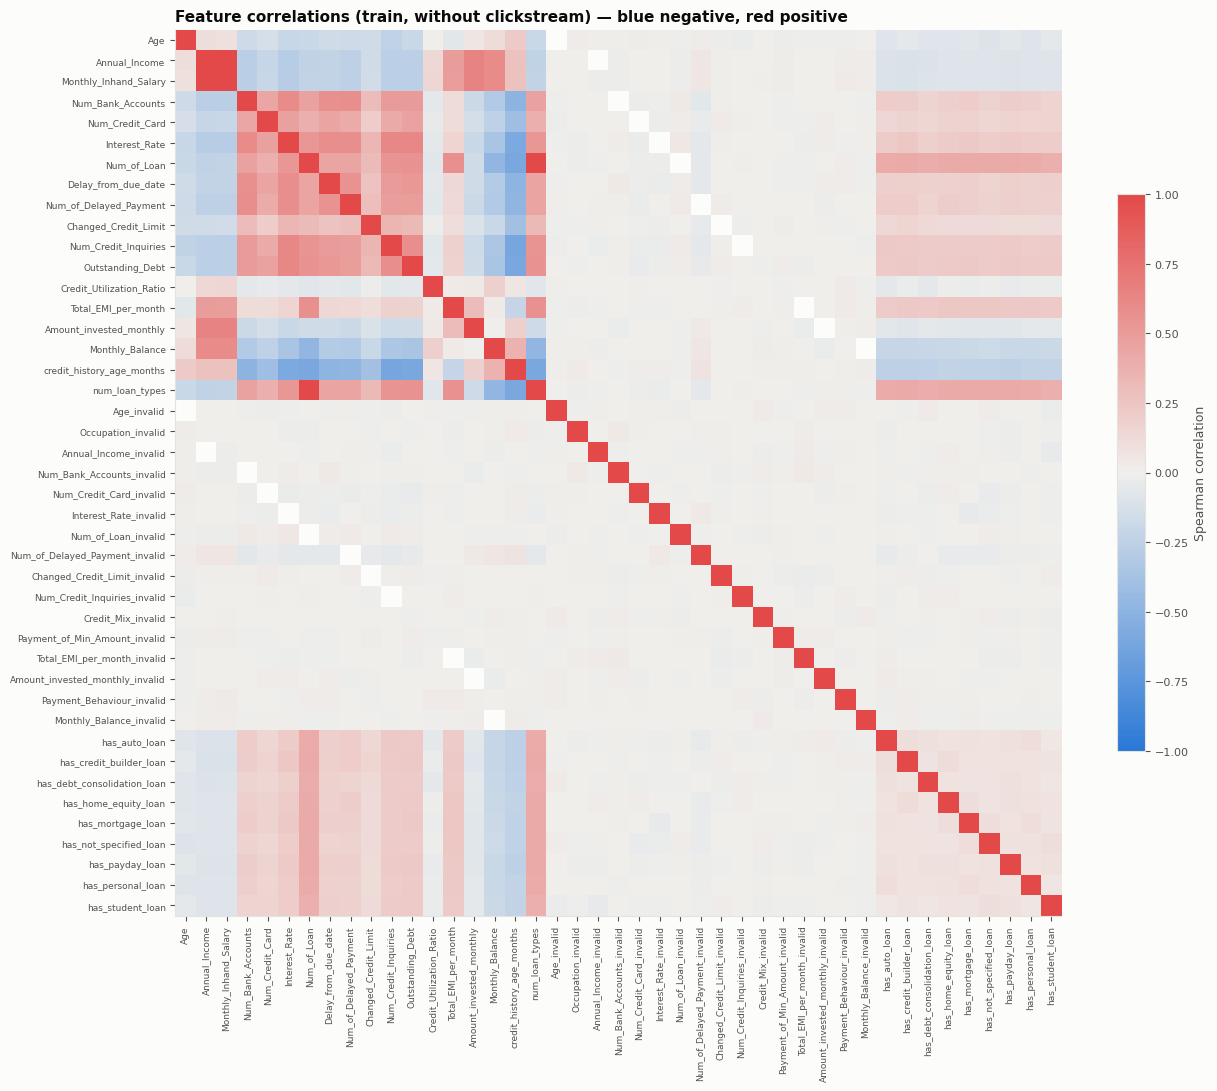

feature_1,feature_2,spearman
Num_of_Loan,num_loan_types,1.000
Annual_Income,Monthly_Inhand_Salary,0.994


In [20]:
corr_cols = [c for c in NUMERIC + BINARY if c not in CLICK and train[c].nunique() > 1]
corr = train[corr_cols].corr(method="spearman")
pairs = (corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1)).stack()
         .rename("spearman").reset_index().rename(columns={"level_0": "feature_1", "level_1": "feature_2"}))
pairs["abs"] = pairs["spearman"].abs()
high_pairs = pairs[pairs["abs"] >= 0.8].sort_values("abs", ascending=False).drop(columns="abs")
high_pairs.to_csv(os.path.join(EDA_DIR, "high_correlation_pairs.csv"), index=False)
click_corr = train[CLICK].corr(method="spearman").where(np.triu(np.ones((20, 20), dtype=bool), k=1)).stack().abs()
print(f"Clickstream fe_1..fe_20: max |Spearman| between them = {click_corr.max():.2f}, mean = {click_corr.mean():.2f}")

from matplotlib.colors import LinearSegmentedColormap
diverging = LinearSegmentedColormap.from_list("div", ["#2a78d6", "#f0efec", "#e34948"])
fig, ax = plt.subplots(figsize=(13, 11))
im = ax.imshow(corr.values, cmap=diverging, vmin=-1, vmax=1)
ax.set_xticks(range(len(corr_cols)), corr_cols, rotation=90, fontsize=6.5)
ax.set_yticks(range(len(corr_cols)), corr_cols, fontsize=6.5)
ax.grid(False)
cb = fig.colorbar(im, ax=ax, shrink=0.6)
cb.set_label("Spearman correlation", color=INK_2)
ax.set_title("Feature correlations (train, without clickstream) — blue negative, red positive")
fig.tight_layout()
fig.savefig(os.path.join(EDA_CHART_DIR, "14_1_feature_correlation.png"), dpi=130, bbox_inches="tight")
plt.show()
high_pairs.style.hide(axis="index").format({"spearman": "{:.3f}"})

### 14b — Feature vs target (train only): IV, univariate AUC, default rate by bin

In [21]:
def binned(x, kind):
    if kind == "numeric" and x.nunique() > 10:
        b = pd.qcut(x, 10, duplicates="drop").astype(str)
    else:
        b = x.astype(object).astype(str)
    return b.where(x.notna(), "Missing")


def woe_iv(x, y, kind):
    t = pd.DataFrame({"bin": binned(x, kind), "y": y}).groupby("bin", sort=False)["y"].agg(["count", "sum"])
    t["good"] = t["count"] - t["sum"]
    pb = (t["sum"] + 0.5) / (t["sum"].sum() + 0.5 * len(t))
    pg = (t["good"] + 0.5) / (t["good"].sum() + 0.5 * len(t))
    t["woe"] = np.log(pg / pb)
    t["iv"] = (pg - pb) * t["woe"]
    t["default_rate"] = t["sum"] / t["count"]
    return t, float(t["iv"].sum())


def univariate_auc(x, y, kind):
    m = x.notna()
    if m.sum() < 50 or x[m].nunique() < 2:
        return np.nan, ""
    score = x[m] if kind != "categorical" else x[m].map(y[m].groupby(x[m]).mean())
    a = roc_auc_score(y[m], score)
    return max(a, 1 - a), ("higher -> more default" if a >= 0.5 else "higher -> less default") if kind != "categorical" else "by category"


def iv_strength(v):
    return ("suspicious (>0.5)" if v > 0.5 else "strong" if v > 0.3 else "medium" if v > 0.1
            else "weak" if v > 0.02 else "not useful")

y = train["label"]
rows, bin_tables = [], {}
for c in FEATURES:
    kind = "categorical" if c in CATEGORICAL else "binary" if c in BINARY else "numeric"
    t, iv = woe_iv(train[c], y, kind)
    auc, direction = univariate_auc(train[c], y, kind)
    bin_tables[c] = t
    miss_rate = t.loc["Missing", "default_rate"] if "Missing" in t.index else np.nan
    rows.append(dict(feature=c, group=group_of(c), kind=kind, in_set_A=c in FEATURES_A, iv=iv,
                     iv_strength=iv_strength(iv), auc=auc, direction=direction,
                     missing_pct=train[c].isna().mean() * 100, default_rate_when_missing=miss_rate))
rel = pd.DataFrame(rows).sort_values("iv", ascending=False).reset_index(drop=True)
rel.to_csv(os.path.join(EDA_DIR, "feature_target_relationships.csv"), index=False)
pd.concat([t.assign(feature=c) for c, t in bin_tables.items()]).reset_index().to_csv(
    os.path.join(EDA_DIR, "feature_target_bins.csv"), index=False)

print("IV strength (train):", rel["iv_strength"].value_counts().to_dict())
print("Mean IV by group:", rel.groupby("group")["iv"].mean().round(3).to_dict())
rel.head(25).style.hide(axis="index").format({"iv": "{:.3f}", "auc": "{:.3f}", "missing_pct": "{:.1f}%",
                                              "default_rate_when_missing": "{:.1%}"}, na_rep="")

IV strength (train): {'not useful': 31, 'weak': 21, 'strong': 7, 'medium': 5, 'suspicious (>0.5)': 4}
Mean IV by group: {'attributes': 0.029, 'clickstream': 0.023, 'financials': 0.192, 'gold-derived': 0.056}


feature,group,kind,in_set_A,iv,iv_strength,auc,direction,missing_pct,default_rate_when_missing
Outstanding_Debt,financials,numeric,True,0.865,suspicious (>0.5),0.725,higher -> more default,0.0%,
Interest_Rate,financials,numeric,True,0.698,suspicious (>0.5),0.715,higher -> more default,2.0%,19.5%
Num_Credit_Inquiries,financials,numeric,True,0.580,suspicious (>0.5),0.709,higher -> more default,1.4%,35.2%
Delay_from_due_date,financials,numeric,True,0.560,suspicious (>0.5),0.698,higher -> more default,0.0%,
credit_history_age_months,financials,numeric,True,0.492,strong,0.690,higher -> less default,0.0%,
Num_Credit_Card,financials,numeric,True,0.455,strong,0.678,higher -> more default,2.4%,25.7%
num_loan_types,financials,numeric,True,0.439,strong,0.671,higher -> more default,0.0%,
Num_of_Loan,financials,numeric,True,0.420,strong,0.671,higher -> more default,4.4%,28.5%
Credit_Mix,financials,categorical,True,0.410,strong,0.680,by category,21.4%,29.7%
Num_Bank_Accounts,financials,numeric,True,0.407,strong,0.660,higher -> more default,1.1%,33.3%


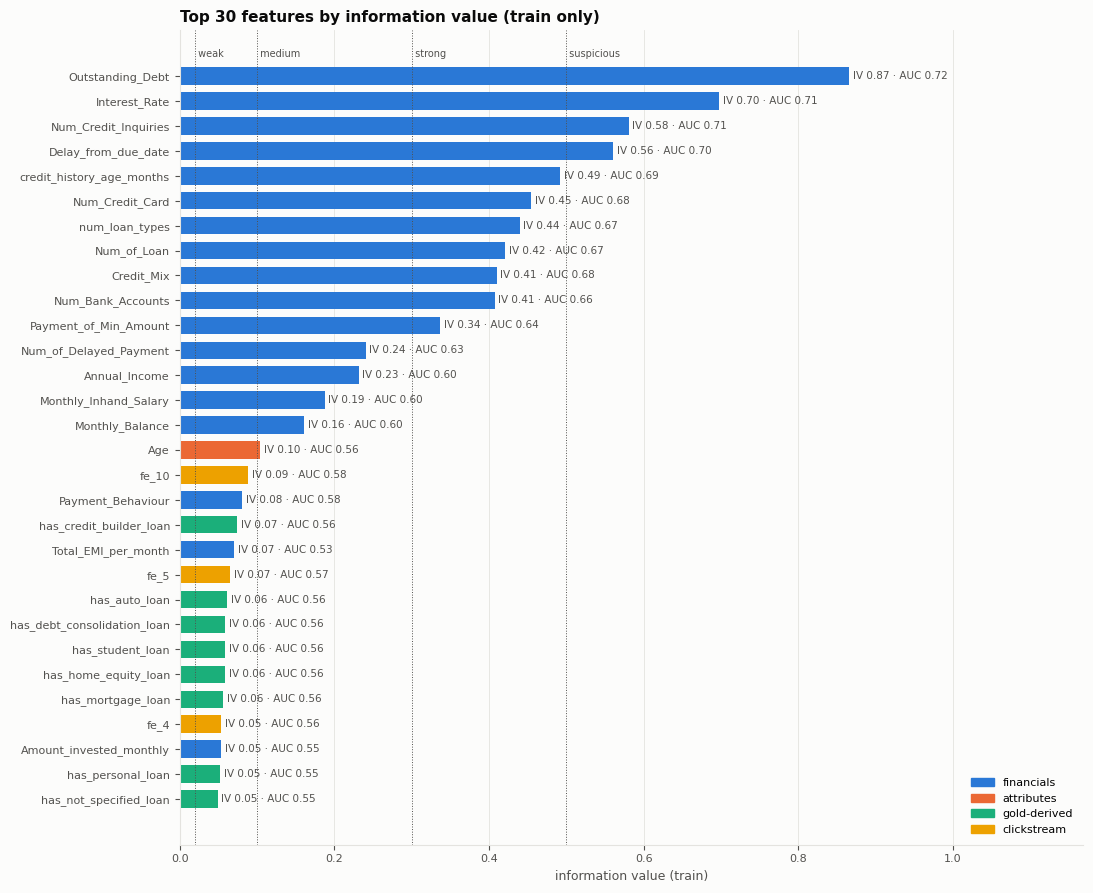

In [22]:
# Chart: feature strength (IV), coloured by feature group
top = rel.head(30).iloc[::-1]
gcolor = {"financials": SERIES[0], "attributes": SERIES[1], "gold-derived": SERIES[2], "clickstream": SERIES[3]}
fig, ax = plt.subplots(figsize=(11, 9))
ax.barh(top["feature"], top["iv"], color=[gcolor[g] for g in top["group"]], height=0.7)
for yv, (iv, auc) in enumerate(zip(top["iv"], top["auc"])):
    ax.text(iv + 0.005, yv, f"IV {iv:.2f} · AUC {auc:.2f}", va="center", fontsize=7.5, color=INK_2)
for x, lab in [(0.02, "weak"), (0.1, "medium"), (0.3, "strong"), (0.5, "suspicious")]:
    ax.axvline(x, color=INK_2, linewidth=0.7, linestyle=":")
    ax.text(x, len(top) - 0.3, f" {lab}", fontsize=7, color=INK_2, va="bottom")
ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=v) for v in gcolor.values()], labels=list(gcolor),
          loc="lower right")
ax.set_xlabel("information value (train)")
ax.grid(axis="y", visible=False)
ax.set_xlim(0, max(top["iv"].max() * 1.35, 0.6))
ax.set_title("Top 30 features by information value (train only)")
fig.tight_layout()
fig.savefig(os.path.join(EDA_CHART_DIR, "14_2_feature_strength_iv.png"), dpi=130, bbox_inches="tight")
plt.show()

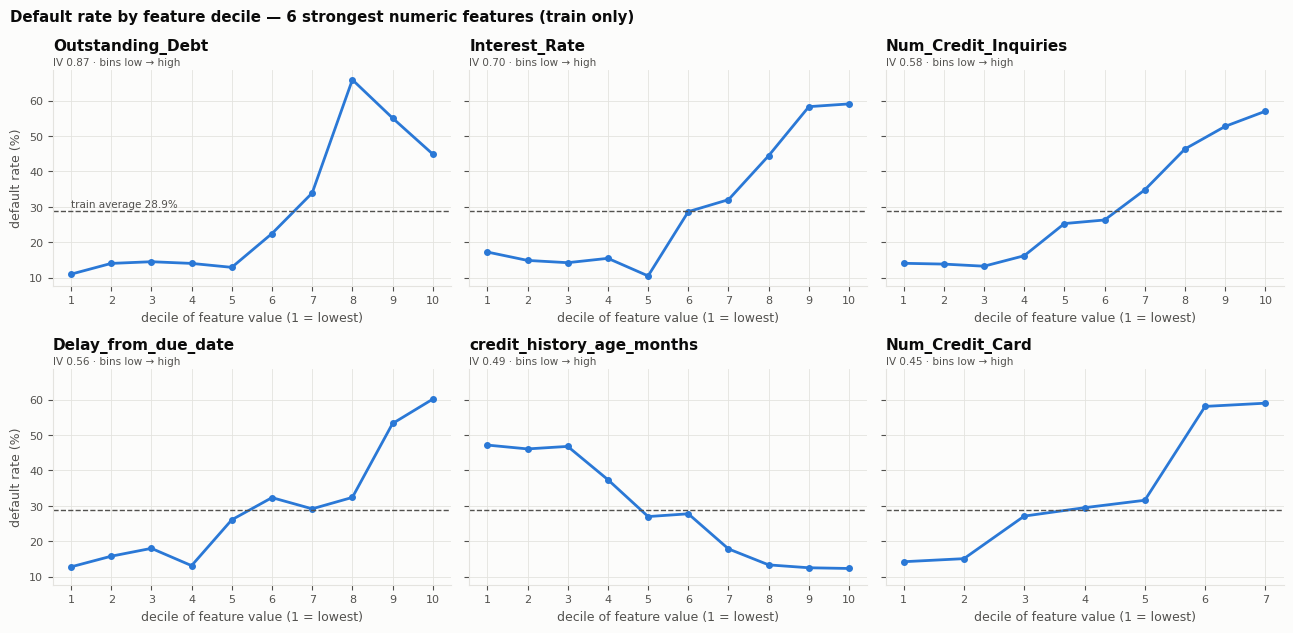

In [23]:
# Chart: default rate by decile for the 6 strongest numeric features (train)
top_num = rel[rel["kind"] == "numeric"].head(6)["feature"].tolist()
base = y.mean() * 100
fig, axes = plt.subplots(2, 3, figsize=(13, 6.4), sharey=True)
for ax, c in zip(axes.flat, top_num):
    t = bin_tables[c].copy()
    t = t[t.index != "Missing"]
    order = sorted(t.index, key=lambda s: float(s.strip("(]").split(",")[0]) if s.startswith("(") else float(s))
    t = t.loc[order]
    xs = np.arange(1, len(t) + 1)
    ax.plot(xs, t["default_rate"] * 100, color=SERIES[0], marker="o", markersize=4)
    ax.axhline(base, color=INK_2, linestyle="--", linewidth=1)
    ax.set_title(c, pad=14)
    ax.text(0, 1.01, f"IV {rel.set_index('feature').loc[c, 'iv']:.2f} · bins low → high",
            transform=ax.transAxes, fontsize=7.5, color=INK_2, va="bottom")
    ax.set_xticks(xs)
    ax.set_xlabel("decile of feature value (1 = lowest)")
for ax in axes[:, 0]:
    ax.set_ylabel("default rate (%)")
axes[0, 0].text(1, base + 1, f"train average {base:.1f}%", fontsize=7.5, color=INK_2)
fig.suptitle("Default rate by feature decile — 6 strongest numeric features (train only)", x=0.01, ha="left",
             fontweight="bold", color=INK)
fig.tight_layout()
fig.savefig(os.path.join(EDA_CHART_DIR, "14_3_default_rate_by_decile.png"), dpi=130, bbox_inches="tight")
plt.show()

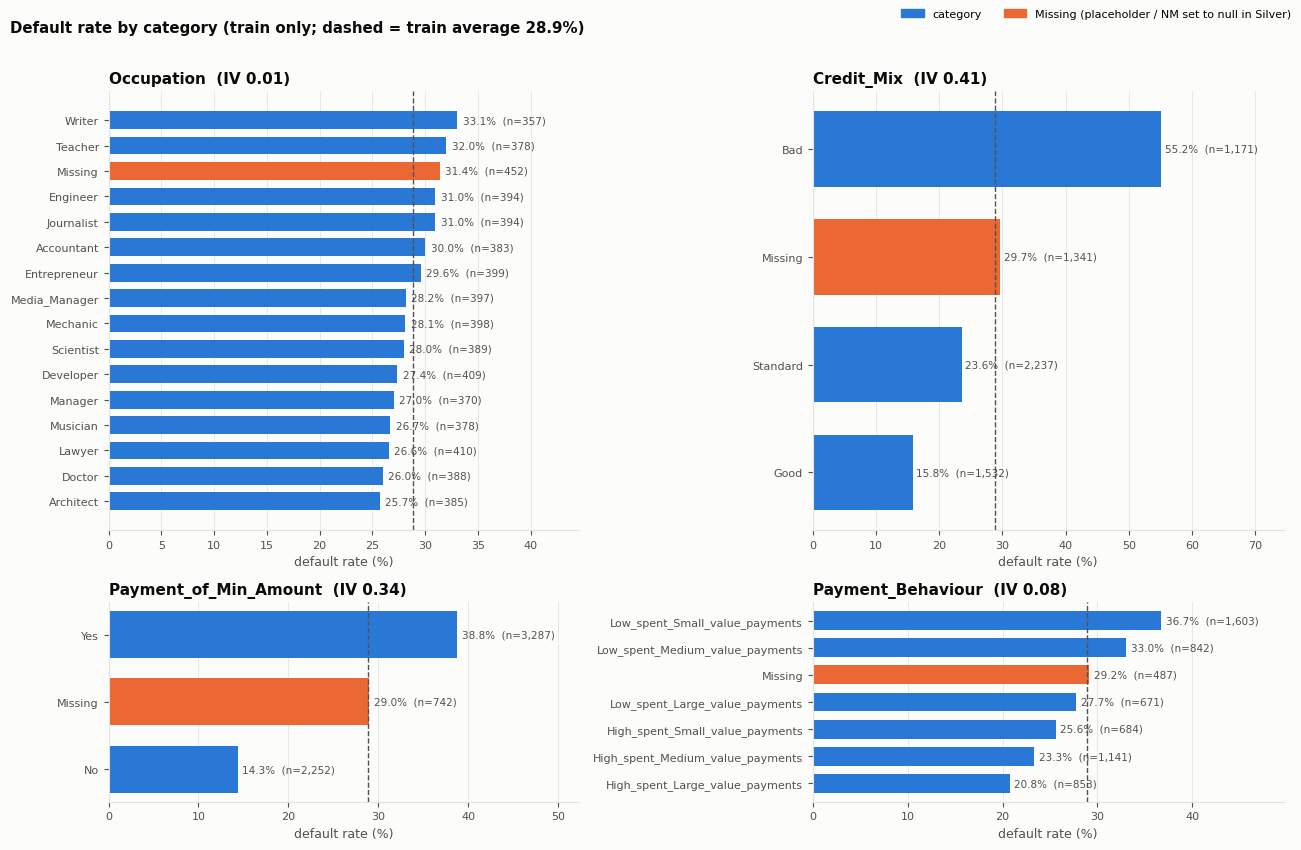

In [24]:
# Chart: default rate by category (train), with 'Missing' (the nulled placeholders / NM) as its own category
fig, axes = plt.subplots(2, 2, figsize=(13, 8.5), gridspec_kw={"height_ratios": [2.2, 1]})
for ax, c in zip(axes.flat, ["Occupation", "Credit_Mix", "Payment_of_Min_Amount", "Payment_Behaviour"]):
    t = bin_tables[c].sort_values("default_rate")
    colors = [SERIES[1] if i == "Missing" else SERIES[0] for i in t.index]
    ax.barh(t.index, t["default_rate"] * 100, color=colors, height=0.7)
    for yv, (r, n) in enumerate(zip(t["default_rate"], t["count"])):
        ax.text(r * 100 + 0.5, yv, f"{r * 100:.1f}%  (n={n:,})", va="center", fontsize=7.5, color=INK_2)
    ax.axvline(base, color=INK_2, linestyle="--", linewidth=1)
    ax.set_xlim(0, t["default_rate"].max() * 100 * 1.35)
    ax.set_title(f"{c}  (IV {rel.set_index('feature').loc[c, 'iv']:.2f})")
    ax.set_xlabel("default rate (%)")
    ax.grid(axis="y", visible=False)
fig.legend([plt.Rectangle((0, 0), 1, 1, color=SERIES[0]), plt.Rectangle((0, 0), 1, 1, color=SERIES[1])],
           ["category", "Missing (placeholder / NM set to null in Silver)"], loc="upper right", ncol=2)
fig.suptitle(f"Default rate by category (train only; dashed = train average {base:.1f}%)", x=0.01, ha="left",
             fontweight="bold", color=INK)
fig.tight_layout(rect=(0, 0, 1, 0.97))
fig.savefig(os.path.join(EDA_CHART_DIR, "14_4_default_rate_by_category.png"), dpi=130, bbox_inches="tight")
plt.show()

### 14b — Target rates by group and by loan-start month (train only)

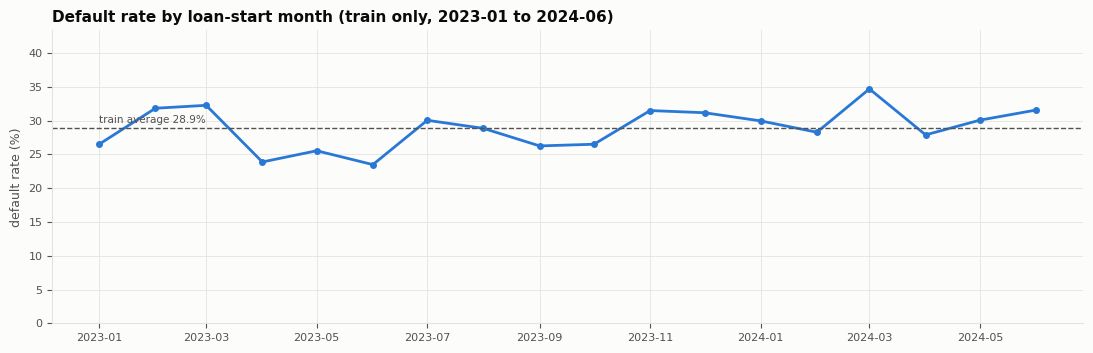

Monthly default rate range (train): 23.5% (2023-06) to 34.7% (2024-03); loans per month 316-377


group_by,value,loans,default_rate_pct
age_band,14-24,1475,31.9%
age_band,25-34,1709,31.2%
age_band,35-44,1774,31.2%
age_band,45+,1157,18.1%
age_band,Missing,166,28.3%
num_loan_types,0,754,12.9%
num_loan_types,1,696,14.1%
num_loan_types,2,964,24.9%
num_loan_types,3,992,23.6%
num_loan_types,4,981,23.0%


In [25]:
def rate_by(col, values=None):
    s = values if values is not None else train[col]
    g = train.assign(_g=s.astype(object).where(s.notna(), "Missing").astype(str)).groupby("_g")["label"]
    return pd.DataFrame({"group_by": col, "value": g.mean().index, "loans": g.size().values,
                         "default_rate_pct": g.mean().values * 100})

age_band = pd.cut(train["Age"], [13, 24, 34, 44, 100], labels=["14-24", "25-34", "35-44", "45+"])
group_rates = pd.concat([
    rate_by("loan_start_month", train[SCORING_COL].dt.strftime("%Y-%m")),
    rate_by("age_band", age_band),
    rate_by("num_loan_types"),
    *[rate_by(c) for c in CATEGORICAL],
    *[rate_by(c) for c in LOAN_TYPE_COLUMNS],
], ignore_index=True)
group_rates.to_csv(os.path.join(EDA_DIR, "target_rates_by_group.csv"), index=False)

m = group_rates[group_rates["group_by"] == "loan_start_month"]
fig, ax = plt.subplots(figsize=(11, 3.6))
ax.plot(pd.to_datetime(m["value"]), m["default_rate_pct"], color=SERIES[0], marker="o", markersize=4)
ax.axhline(base, color=INK_2, linestyle="--", linewidth=1)
ax.text(pd.to_datetime(m["value"]).iloc[0], base + 0.8, f"train average {base:.1f}%", fontsize=7.5, color=INK_2)
ax.set_ylim(0, m["default_rate_pct"].max() * 1.25)
ax.set_ylabel("default rate (%)")
ax.set_title("Default rate by loan-start month (train only, 2023-01 to 2024-06)")
fig.tight_layout()
fig.savefig(os.path.join(EDA_CHART_DIR, "14_5_default_rate_by_month.png"), dpi=130, bbox_inches="tight")
plt.show()
lo, hi = m.loc[m["default_rate_pct"].idxmin()], m.loc[m["default_rate_pct"].idxmax()]
print(f"Monthly default rate range (train): {lo['default_rate_pct']:.1f}% ({lo['value']}) to "
      f"{hi['default_rate_pct']:.1f}% ({hi['value']}); loans per month {m['loans'].min()}-{m['loans'].max()}")
group_rates[group_rates["group_by"].isin(["age_band", "num_loan_types"])].style.hide(axis="index").format(
    {"default_rate_pct": "{:.1f}%"})

### 14b — Leakage watchlist (train only)

Every feature passed the structural checks in step 13 (point-in-time, no label-source columns). The watchlist adds **statistical** warning signs, each with a risk level and a proposed action (decided in step 15):

| Signal | Why it matters |
|---|---|
| IV > 0.5 or univariate AUC > 0.85 | Too good to be true for one feature — check it is not a disguised outcome |
| Missingness strongly related to default (missing-bin rate ≥ 5 pp from average) | Missing values carry signal — keep a missing indicator; check it is not a process artefact |
| Correlated with loan-start month (\|Spearman\| ≥ 0.3) | Possible time proxy — could encode drift rather than customer risk |
| Constant / near-constant in train (top value ≥ 99.5%) | No information — candidate for removal in step 23 |
| Near-duplicate of another feature (\|Spearman\| ≥ 0.8) | Redundant — keep one in step 23 |

In [26]:
month_num = train[SCORING_COL].dt.year * 12 + train[SCORING_COL].dt.month
watch = []
def flag(feature, signal, evidence, risk, proposed):
    watch.append(dict(feature=feature, group=group_of(feature), signal=signal, evidence=evidence, risk=risk,
                      proposed_action=proposed))

for _, r in rel.iterrows():
    c = r["feature"]
    if r["iv"] > 0.5 or (pd.notna(r["auc"]) and r["auc"] > 0.85):
        flag(c, "suspiciously strong", f"IV {r['iv']:.2f}, AUC {r['auc']:.2f}", "high",
             "investigate: confirm it is known at loan start and not derived from repayment")
    if pd.notna(r["default_rate_when_missing"]) and abs(r["default_rate_when_missing"] - y.mean()) * 100 >= 5 \
            and r["missing_pct"] >= 0.5:
        flag(c, "informative missingness", f"default rate {r['default_rate_when_missing']:.1%} when missing "
             f"vs {y.mean():.1%}; {r['missing_pct']:.1f}% missing", "medium",
             "keep the _invalid flag / missing indicator in step 18; do not drop rows")
    if r["kind"] != "categorical" and train[c].nunique() > 1:
        rho = pd.Series(train[c]).corr(month_num, method="spearman")
        if abs(rho) >= 0.3:
            flag(c, "possible time proxy", f"Spearman with loan-start month {rho:+.2f}", "medium",
                 "check drift in step 16; consider excluding if it only encodes time")
    top_share = train[c].value_counts(normalize=True, dropna=False).iloc[0]
    if top_share >= 0.995:
        flag(c, "constant / near-constant", f"top value covers {top_share:.1%} of train", "low",
             "candidate for removal in step 23")
for _, p in high_pairs.iterrows():
    flag(p["feature_1"], "near-duplicate", f"Spearman {p['spearman']:+.2f} with {p['feature_2']}", "low",
         "keep one of the pair in step 23")

watchlist = pd.DataFrame(watch, columns=["feature", "group", "signal", "evidence", "risk", "proposed_action"])
watchlist.to_csv(os.path.join(EDA_DIR, "leakage_watchlist.csv"), index=False)
print("Watchlist:", watchlist["signal"].value_counts().to_dict() if len(watchlist) else "empty")
watchlist.style.hide(axis="index")

Watchlist: {'suspiciously strong': 4, 'informative missingness': 4, 'constant / near-constant': 2, 'near-duplicate': 2}


feature,group,signal,evidence,risk,proposed_action
Outstanding_Debt,financials,suspiciously strong,"IV 0.87, AUC 0.72",high,investigate: confirm it is known at loan start and not derived from repayment
Interest_Rate,financials,suspiciously strong,"IV 0.70, AUC 0.71",high,investigate: confirm it is known at loan start and not derived from repayment
Interest_Rate,financials,informative missingness,default rate 19.5% when missing vs 28.9%; 2.0% missing,medium,keep the _invalid flag / missing indicator in step 18; do not drop rows
Num_Credit_Inquiries,financials,suspiciously strong,"IV 0.58, AUC 0.71",high,investigate: confirm it is known at loan start and not derived from repayment
Num_Credit_Inquiries,financials,informative missingness,default rate 35.2% when missing vs 28.9%; 1.4% missing,medium,keep the _invalid flag / missing indicator in step 18; do not drop rows
Delay_from_due_date,financials,suspiciously strong,"IV 0.56, AUC 0.70",high,investigate: confirm it is known at loan start and not derived from repayment
Num_of_Delayed_Payment,financials,informative missingness,default rate 23.5% when missing vs 28.9%; 1.6% missing,medium,keep the _invalid flag / missing indicator in step 18; do not drop rows
Changed_Credit_Limit,financials,informative missingness,default rate 34.6% when missing vs 28.9%; 2.2% missing,medium,keep the _invalid flag / missing indicator in step 18; do not drop rows
Monthly_Balance_invalid,financials,constant / near-constant,top value covers 100.0% of train,low,candidate for removal in step 23
type_of_loan_unknown,financials,constant / near-constant,top value covers 100.0% of train,low,candidate for removal in step 23


In [27]:
# Model A vs B preview: how much signal does clickstream add on its own? (train only, univariate)
ab = rel.assign(set=np.where(rel["group"] == "clickstream", "clickstream (B only)", "set A features"))
summary_ab = ab.groupby("set").agg(features=("feature", "size"), max_iv=("iv", "max"), mean_iv=("iv", "mean"),
                                   max_auc=("auc", "max"), useful_iv_ge_0_02=("iv", lambda s: int((s >= 0.02).sum())))
summary_ab.to_csv(os.path.join(EDA_DIR, "model_a_vs_b_signal_preview.csv"))
summary_ab.style.format({"max_iv": "{:.3f}", "mean_iv": "{:.3f}", "max_auc": "{:.3f}"})

,features,max_iv,mean_iv,max_auc,useful_iv_ge_0_02
set,,,,,
clickstream (B only),20,0.089,0.023,0.579,8
set A features,48,0.865,0.153,0.725,29


### Step 14 outputs (`datamart/gold/_eda/`)

`missing_by_partition.csv`, `high_correlation_pairs.csv`, `feature_target_relationships.csv` (IV, AUC, direction, missingness per feature), `feature_target_bins.csv` (default rate and WOE per bin), `target_rates_by_group.csv`, `leakage_watchlist.csv`, `model_a_vs_b_signal_preview.csv`, charts `14_1`–`14_5`. Univariate strength is **not** causal and ignores interactions — it guides steps 15, 23 and 27, it does not select the model.

---

## Step 16 — Temporal quality

Not time-series modelling: checks for **time-related data problems** at each relevant grain (source snapshot month, loan-start cohort).

| # | Check | Data used |
|---|---|---|
| 1 | Missing periods / irregular sampling (sources, cohorts, clickstream panel) | all, no labels |
| 2 | Freshness of each source vs the as-of date | Bronze audit |
| 3 | Coverage breaks over time | all, no labels |
| 4a | Feature drift **inside training** (early vs late cohorts) — may inform decisions | train, no labels |
| 4b | Feature drift **development vs OOT** — **information only**, never used to choose features | features only, no labels |
| 5 | Label drift: monthly default rate with control limits, trend, homogeneity test | **train only** |
| 6 | Seasonality | volume (all), label (train) |
| 7 | Look-ahead risks | tests from steps 10, 11, 13, 17 |
| 8 | Extreme months: valid event or error? | cohort medians, volumes |

**PSI** (population stability index): < 0.1 stable · 0.1–0.25 moderate shift · > 0.25 large shift. Monthly cohorts have ~500 loans, so small PSI values are partly sampling noise.

In [28]:
from scipy.stats import chi2_contingency

temporal = []
def tq(check, grain, status, finding, evidence, action):
    temporal.append(dict(check=check, grain=grain, status=status, finding=finding, evidence=evidence, action=action))

def months_between(lo, hi):
    return pd.period_range(pd.Timestamp(lo).to_period("M"), pd.Timestamp(hi).to_period("M"), freq="M")

# 1. Missing periods / irregular sampling
for t in [LABEL_TABLE] + FEATURE_TABLES:
    cnt = frames[t].groupby("snapshot_date").count().toPandas()
    cnt["snapshot_date"] = pd.to_datetime(cnt["snapshot_date"].astype(str))
    exp = months_between(cnt["snapshot_date"].min(), cnt["snapshot_date"].max())
    missing = sorted(set(exp) - set(cnt["snapshot_date"].dt.to_period("M")))
    cv = cnt["count"].std() / cnt["count"].mean()
    tq("missing periods / sampling", f"{t} snapshot month", "PASS" if not missing else "FAIL",
       f"{len(exp)} months, {len(missing)} missing", f"rows per month CV {cv:.2f}",
       "none" if not missing else "investigate missing months")

coh = data.groupby(data[SCORING_COL].dt.to_period("M")).size()
exp = months_between(coh.index.min().to_timestamp(), coh.index.max().to_timestamp())
tq("missing periods / sampling", "loan-start cohort", "PASS" if set(exp) == set(coh.index) else "FAIL",
   f"{len(coh)} cohorts {coh.index.min()}..{coh.index.max()}, none missing",
   f"loans per cohort {coh.min()}-{coh.max()} (CV {coh.std() / coh.mean():.2f})", "none")

panel = frames["feature_clickstream"].groupby("Customer_ID").count().toPandas()["count"]
tq("missing periods / sampling", "clickstream customer panel", "PASS" if panel.nunique() == 1 else "WARN",
   f"{len(panel):,} customers, snapshots per customer: {sorted(panel.unique())}",
   "every covered customer observed every month 2023-01..2024-12", "none")

# 2. Freshness (from the Bronze audit)
audit = pd.read_csv(os.path.join(PROJECT_DIR, "datamart", "bronze", "_audit", "audit_report.csv"))
for _, a in audit[audit["check"] == "freshness"].iterrows():
    tq("freshness", f"{a['table']} snapshot month", a["status"], a["observed"], "Bronze audit (step 03)",
       "none" if a["status"] == "PASS" else
       "accept: historical extract; features are taken as of each loan's start, so later loans use the latest "
       "available snapshot (as-of rule)")

# 3. Coverage breaks over time (availability by cohort, from step 10)
for t in FEATURE_TABLES:
    s = cov.set_index(SCORING_COL)[SHORT[t]] * 100
    jumps = s.diff().abs()
    if (jumps > 50).any():
        when = jumps.idxmax()
        tq("coverage break", f"{t} by loan-start cohort", "WARN",
           f"availability changes from {s.shift(1)[when]:.0f}% to {s[when]:.0f}% at {when:%Y-%m}",
           f"{(s == 0).sum()} cohorts with 0% coverage",
           "accept: model A (no clickstream) is the champion and is evaluated on OOT; model B (with clickstream) "
           "is compared on train/validation/test and an in-development time check; no has_clickstream flag (time proxy)")
    else:
        tq("coverage break", f"{t} by loan-start cohort", "PASS", f"availability {s.min():.0f}%-{s.max():.0f}% in every cohort",
           "", "none")
print("Checks 1-3 done")

Checks 1-3 done


In [29]:
# 4. Feature drift — PSI per feature
def psi_num(e, a):
    e, a = pd.Series(e).dropna().astype(float), pd.Series(a).dropna().astype(float)
    return silver.psi(e.values, a.values) if len(e) and len(a) else np.nan

def psi_cat(e, a):
    e, a = pd.Series(e).fillna("Missing"), pd.Series(a).fillna("Missing")
    cats = sorted(set(e) | set(a))
    pe = e.value_counts(normalize=True).reindex(cats).fillna(0).clip(lower=1e-6)
    pa = a.value_counts(normalize=True).reindex(cats).fillna(0).clip(lower=1e-6)
    return float(((pa - pe) * np.log(pa / pe)).sum())

def psi_feature(c, e, a):
    # categorical and 0/1 flags: PSI on value shares (handles near-constant flags); numeric: decile PSI
    return psi_cat(e, a) if c in CATEGORICAL + BINARY else psi_num(e, a)

train_feats = data[data["partition"] == "train"]
dev_feats = data[data["partition"] != "oot"]
oot_feats = data[data["partition"] == "oot"]
early = train_feats[train_feats[SCORING_COL] < "2023-10-01"]
late = train_feats[train_feats[SCORING_COL] >= "2023-10-01"]

drift = pd.DataFrame([dict(feature=c, group=group_of(c),
                           psi_train_early_vs_late=psi_feature(c, early[c], late[c]),
                           psi_dev_vs_oot=psi_feature(c, dev_feats[c], oot_feats[c]) if c not in CLICK else np.nan,
                           missing_pct_dev=dev_feats[c].isna().mean() * 100,
                           missing_pct_oot=oot_feats[c].isna().mean() * 100)
                      for c in FEATURES])
band = lambda v: "large (>0.25)" if v > 0.25 else "moderate (0.1-0.25)" if v > 0.1 else "stable (<0.1)"
drift["train_drift"] = drift["psi_train_early_vs_late"].map(band)
drift["oot_drift_info_only"] = drift["psi_dev_vs_oot"].map(lambda v: band(v) if pd.notna(v) else "n/a (no clickstream in OOT)")
drift = drift.sort_values("psi_dev_vs_oot", ascending=False)
drift.to_csv(os.path.join(EDA_DIR, "feature_drift_psi.csv"), index=False)

n_train_shift = int((drift["psi_train_early_vs_late"] > 0.1).sum())
n_oot_shift = int((drift["psi_dev_vs_oot"] > 0.1).sum())
tq("feature drift (inside training)", "train cohorts 2023-01..09 vs 2023-10..2024-06", "PASS" if n_train_shift == 0 else "WARN",
   f"{n_train_shift} features with PSI > 0.1; max {drift['psi_train_early_vs_late'].max():.3f}",
   "features only", "none" if n_train_shift == 0 else "review drifting features in step 23")
tq("feature drift (development vs OOT, info only)", "dev 2023-01..2024-06 vs OOT 2024-07..2025-01",
   "PASS" if n_oot_shift == 0 else "WARN",
   f"{n_oot_shift} set-A features with PSI > 0.1; max {drift['psi_dev_vs_oot'].max():.3f}",
   "features only; never used for feature decisions",
   "none" if n_oot_shift == 0 else "explain in step 32 (robustness) and monitor in step 35")
drift.head(15).style.hide(axis="index").format({"psi_train_early_vs_late": "{:.3f}", "psi_dev_vs_oot": "{:.3f}",
                                               "missing_pct_dev": "{:.1f}%", "missing_pct_oot": "{:.1f}%"}, na_rep="—")

feature,group,psi_train_early_vs_late,psi_dev_vs_oot,missing_pct_dev,missing_pct_oot,train_drift,oot_drift_info_only
Monthly_Balance,financials,0.004,0.007,0.0%,0.0%,stable (<0.1),stable (<0.1)
Total_EMI_per_month,financials,0.007,0.006,3.1%,3.3%,stable (<0.1),stable (<0.1)
Age,attributes,0.006,0.006,2.6%,2.5%,stable (<0.1),stable (<0.1)
Interest_Rate,financials,0.004,0.006,2.1%,2.2%,stable (<0.1),stable (<0.1)
Num_of_Delayed_Payment,financials,0.002,0.004,1.5%,1.4%,stable (<0.1),stable (<0.1)
Changed_Credit_Limit,financials,0.005,0.004,2.1%,1.8%,stable (<0.1),stable (<0.1)
Amount_invested_monthly,financials,0.007,0.004,4.4%,4.6%,stable (<0.1),stable (<0.1)
Occupation,attributes,0.013,0.004,6.9%,7.3%,stable (<0.1),stable (<0.1)
Num_Credit_Card,financials,0.003,0.003,2.4%,2.1%,stable (<0.1),stable (<0.1)
Delay_from_due_date,financials,0.002,0.003,0.0%,0.0%,stable (<0.1),stable (<0.1)


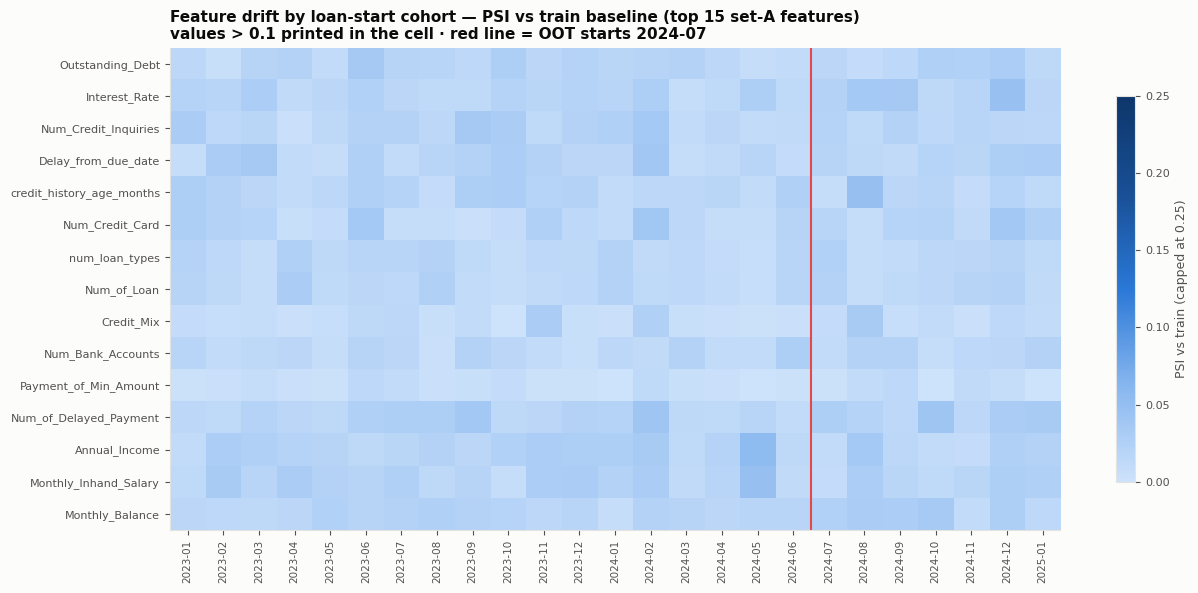

In [30]:
# Chart: PSI of the strongest set-A features per loan-start cohort, baseline = train (features only)
heat_feats = [c for c in rel["feature"] if c in FEATURES_A][:15]
months_all = sorted(data[SCORING_COL].dt.to_period("M").unique())
heat = pd.DataFrame({str(m): [psi_feature(c, train_feats[c], data.loc[data[SCORING_COL].dt.to_period("M") == m, c])
                               for c in heat_feats] for m in months_all}, index=heat_feats)
heat.to_csv(os.path.join(EDA_DIR, "feature_psi_by_cohort.csv"))

from matplotlib.colors import LinearSegmentedColormap, BoundaryNorm
seq = LinearSegmentedColormap.from_list("seq", ["#cde2fb", "#86b6ef", "#2a78d6", "#184f95", "#0d366b"])
fig, ax = plt.subplots(figsize=(13, 6))
im = ax.imshow(heat.values, cmap=seq, vmin=0, vmax=0.25, aspect="auto")
ax.set_xticks(range(len(months_all)), [str(m) for m in months_all], rotation=90, fontsize=7.5)
ax.set_yticks(range(len(heat_feats)), heat_feats, fontsize=8)
ax.grid(False)
oot_idx = [str(m) for m in months_all].index("2024-07")
ax.axvline(oot_idx - 0.5, color="#e34948", linewidth=1.5)
for i in range(heat.shape[0]):
    for j in range(heat.shape[1]):
        v = heat.values[i, j]
        if v > 0.1:
            ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=6.5, color="white")
cb = fig.colorbar(im, ax=ax, shrink=0.8)
cb.set_label("PSI vs train (capped at 0.25)", color=INK_2)
ax.set_title("Feature drift by loan-start cohort — PSI vs train baseline (top 15 set-A features)\n"
             "values > 0.1 printed in the cell · red line = OOT starts 2024-07", loc="left")
fig.tight_layout()
fig.savefig(os.path.join(EDA_CHART_DIR, "16_1_feature_psi_by_cohort.png"), dpi=130, bbox_inches="tight")
plt.show()

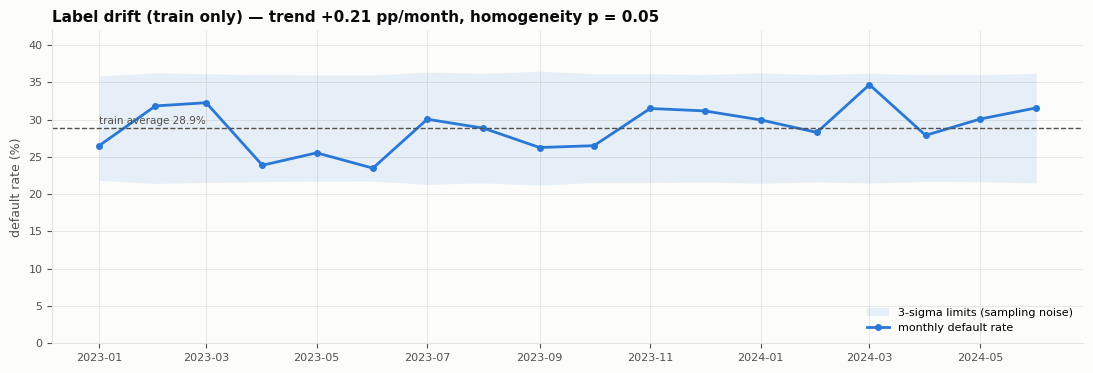

Temporal quality: {'PASS': 14, 'WARN': 5, 'INFO': 1}


check,grain,status,finding,evidence,action
missing periods / sampling,lms_loan_daily snapshot month,✔ PASS,"35 months, 0 missing",rows per month CV 0.44,none
missing periods / sampling,features_attributes snapshot month,✔ PASS,"25 months, 0 missing",rows per month CV 0.04,none
missing periods / sampling,features_financials snapshot month,✔ PASS,"25 months, 0 missing",rows per month CV 0.04,none
missing periods / sampling,feature_clickstream snapshot month,✔ PASS,"24 months, 0 missing",rows per month CV 0.00,none
missing periods / sampling,loan-start cohort,✔ PASS,"25 cohorts 2023-01..2025-01, none missing",loans per cohort 454-543 (CV 0.04),none
missing periods / sampling,clickstream customer panel,✔ PASS,"8,974 customers, snapshots per customer: [24]",every covered customer observed every month 2023-01..2024-12,none
freshness,lms_loan_daily snapshot month,✔ PASS,"latest snapshot 2025-11-01, 0 month(s) behind 2025-11-01",Bronze audit (step 03),none
freshness,feature_clickstream snapshot month,▲ WARN,"latest snapshot 2024-12-01, 11 month(s) behind 2025-11-01",Bronze audit (step 03),"accept: historical extract; features are taken as of each loan's start, so later loans use the latest available snapshot (as-of rule)"
freshness,features_attributes snapshot month,▲ WARN,"latest snapshot 2025-01-01, 10 month(s) behind 2025-11-01",Bronze audit (step 03),"accept: historical extract; features are taken as of each loan's start, so later loans use the latest available snapshot (as-of rule)"
freshness,features_financials snapshot month,▲ WARN,"latest snapshot 2025-01-01, 10 month(s) behind 2025-11-01",Bronze audit (step 03),"accept: historical extract; features are taken as of each loan's start, so later loans use the latest available snapshot (as-of rule)"


In [31]:
# 5. Label drift — train only: control chart, trend, homogeneity test
lm = (train.groupby(train[SCORING_COL].dt.to_period("M"))["label"].agg(["size", "sum", "mean"])
      .rename(columns={"size": "loans", "sum": "defaults", "mean": "rate"}))
p = train["label"].mean()
lm["lcl"] = p - 3 * np.sqrt(p * (1 - p) / lm["loans"])
lm["ucl"] = p + 3 * np.sqrt(p * (1 - p) / lm["loans"])
outside = lm[(lm["rate"] < lm["lcl"]) | (lm["rate"] > lm["ucl"])]
slope = np.polyfit(np.arange(len(lm)), lm["rate"] * 100, 1)[0]
chi2, pval, _, _ = chi2_contingency(np.vstack([lm["defaults"], lm["loans"] - lm["defaults"]]))
lm.to_csv(os.path.join(EDA_DIR, "label_rate_by_month_train.csv"))
tq("label drift (train only)", "loan-start month", "PASS" if outside.empty and pval >= 0.01 else "WARN",
   f"monthly default rate {lm['rate'].min():.1%}-{lm['rate'].max():.1%}; {len(outside)} month(s) outside 3-sigma limits",
   f"trend {slope:+.2f} pp/month; chi-square homogeneity p = {pval:.3f}",
   "none — variation consistent with sampling noise" if outside.empty and pval >= 0.01
   else "monitor; compare in-time test vs OOT performance in step 31-32")

fig, ax = plt.subplots(figsize=(11, 3.8))
x = lm.index.to_timestamp()
ax.fill_between(x, lm["lcl"] * 100, lm["ucl"] * 100, color=SERIES[0], alpha=0.10, lw=0, label="3-sigma limits (sampling noise)")
ax.plot(x, lm["rate"] * 100, color=SERIES[0], marker="o", markersize=4, label="monthly default rate")
ax.axhline(p * 100, color=INK_2, linestyle="--", linewidth=1)
ax.text(x[0], p * 100 + 0.6, f"train average {p * 100:.1f}%", fontsize=7.5, color=INK_2)
ax.set_ylim(0, lm["ucl"].max() * 100 * 1.15)
ax.set_ylabel("default rate (%)")
ax.legend(loc="lower right")
ax.set_title(f"Label drift (train only) — trend {slope:+.2f} pp/month, homogeneity p = {pval:.2f}")
fig.tight_layout()
fig.savefig(os.path.join(EDA_CHART_DIR, "16_2_label_rate_control_chart.png"), dpi=130, bbox_inches="tight")
plt.show()

# 6. Seasonality
vol = data.groupby(data[SCORING_COL].dt.to_period("M")).size()
v23 = vol[[m for m in vol.index if m.year == 2023]].values
v24 = vol[[m for m in vol.index if m.year == 2024]].values
r_season = np.corrcoef(v23, v24)[0, 1]
tq("seasonality", "loan volume by calendar month", "INFO",
   f"2023 vs 2024 monthly volumes correlation {r_season:+.2f} (no repeating pattern)" if abs(r_season) < 0.5
   else f"2023 vs 2024 monthly volumes correlation {r_season:+.2f}",
   "labels: only 18 training months (1.5 cycles) — seasonality of default cannot be assessed reliably",
   "none; revisit when more history is available")

# 7. Look-ahead risks (tests already in place)
tq("look-ahead risk", "features", "PASS", "no feature dated after loan_start_date",
   "step 10 future-exclusion test, step 11 historical replay, step 13 point-in-time check (0 rows)", "none")
split_checks = pd.read_csv(os.path.join(GOLD_DIR, "split", "v1", "split_checks.csv"))
ow = split_checks[split_checks["check"].str.startswith("outcome window")].iloc[0]
tq("look-ahead risk", "labels vs OOT", ow["status"], ow["observed"], "step 17 check 7",
   "accept (documented): features are point-in-time; a strict 6-month embargo would drop ~2,500 training loans")

# 8. Extreme months: valid events or errors?
med = data.groupby(data[SCORING_COL].dt.to_period("M"))[[c for c in heat_feats if c not in CATEGORICAL]].median()
rz = (med - med.median()) / (1.4826 * (med - med.median()).abs().median()).replace(0, np.nan)
extreme = rz.abs().gt(3.5).stack()
extreme = extreme[extreme]
tq("extreme months", "cohort medians of top features", "PASS" if extreme.empty else "WARN",
   f"{len(extreme)} cohort/feature medians beyond 3.5 robust z" + ("" if extreme.empty else
   f": {', '.join(f'{m} {c}' for m, c in extreme.index[:5])}"),
   "loan volume per cohort 456-543 (no spikes)", "none" if extreme.empty else "inspect those cohorts")

temporal_report = pd.DataFrame(temporal)
temporal_report.to_csv(os.path.join(EDA_DIR, "temporal_quality_report.csv"), index=False)
STATUS_STYLE.update({"WARN": ("▲ WARN", "#fdf0d2"), "INFO": ("ℹ INFO", "#e3eefb")})
print("Temporal quality:", temporal_report["status"].value_counts().to_dict())
view = temporal_report.assign(status=temporal_report["status"].map(lambda s: STATUS_STYLE[s][0]))
view.style.apply(lambda col: [f"background-color: {STATUS_STYLE[v.split()[-1]][1]}" for v in col],
                 subset=["status"]).hide(axis="index")

---

## Step 15 — EDA findings → actions (action register)

One register for **every finding from Bronze (03/04), Silver (05–08), Gold (13–14), temporal quality (16) and the split (17)**. Each gets an **action** (correct / transform / investigate / exclude / accept), an **owner**, a **rationale**, a **verification** and a **status**:

| Status | Meaning |
|---|---|
| `closed` | done and verified (e.g. cleaned in Silver and checked by a rule) |
| `assigned` | decided; implemented in a named later step (e.g. step 18 or 23) |
| `accepted` | accepted risk / exception with documented rationale |
| `open` | not decided — **not allowed before modelling** (Gate 2) |

In [32]:
OWNER = CONTRACT["contract"]["owner"]
REG_COLS = ["register_id", "source_step", "layer", "table", "column", "finding", "severity", "action",
            "rationale", "verification", "implemented_in", "owner", "status"]
register = []
def reg(rid, step, layer, table, column, finding, severity, action, rationale, verification, implemented_in, status):
    register.append(dict(register_id=rid, source_step=step, layer=layer, table=table, column=column, finding=finding,
                         severity=severity, action=action, rationale=rationale, verification=verification,
                         implemented_in=implemented_in, owner=OWNER, status=status))

# Bronze + Silver findings (decision register from the Silver layer)
sd = pd.read_csv(os.path.join(PROJECT_DIR, "datamart", "silver", "_reports", "silver_decisions.csv"))
for _, r in sd.iterrows():
    step = "03" if str(r["issue_id"]).startswith("AUD") else "08" if str(r["issue_id"]).startswith("S08") else "04"
    if r["decision"] != "defer":
        reg(r["issue_id"], step, "bronze/silver", r["table"], r["column"], r["finding"], r["severity"], r["decision"],
            r["action"], r["verified_by"], "Silver (steps 05-09)", "accepted" if r["decision"] == "accept" else "closed")
    elif r["category"] == "coverage" and r["column"] == "Customer_ID":
        reg(r["issue_id"], step, "bronze/silver", r["table"], r["column"], r["finding"], r["severity"], "accept",
            "coverage is a time break (100% of loans starting <= 2024-06, 0% after): model A without clickstream "
            "(champion, OOT-evaluable) vs model B with clickstream (challenger); no has_clickstream flag (time proxy)",
            "step 10 join diagnostics; step 16 coverage-break check; step 25 comparison", "steps 10, 16, 25", "assigned")
    else:
        reg(r["issue_id"], step, "bronze/silver", r["table"], r["column"], r["finding"], r["severity"], "accept",
            "historical extract: the as-of join takes the latest snapshot on or before each loan's start",
            "step 13 point-in-time check; step 11 historical replay", "Gold (steps 10-13)", "closed")

# Gold step 14 — leakage watchlist
for i, w in watchlist.reset_index(drop=True).iterrows():
    rid = f"G14-{i + 1:03d}"
    if w["signal"] == "suspiciously strong":
        reg(rid, "14", "gold", "feature_store/v1", w["feature"], f"suspiciously strong ({w['evidence']})", "high", "accept",
            "univariate AUC ~0.70-0.72 is far below leakage levels (>0.9); value known at application (financial "
            "snapshot dated in the loan-start month, as-of verified); classic credit-risk driver; IV inflated by decile "
            "binning", "step 13 point-in-time + no-label-in-X checks; re-check importance stability in step 27",
            "step 27 (re-check)", "accepted")
    elif w["signal"] == "informative missingness":
        reg(rid, "14", "gold", "feature_store/v1", w["feature"], f"informative missingness ({w['evidence']})", "medium",
            "transform", "keep the <column>_invalid flag / add a missing indicator; impute on train only",
            "step 18 fit/transform tests", "step 18", "assigned")
    elif w["signal"] == "constant / near-constant":
        reg(rid, "14", "gold", "feature_store/v1", w["feature"], f"constant ({w['evidence']})", "low", "exclude",
            "no information in train", "step 23 filter report", "step 23", "assigned")
    elif w["signal"] == "near-duplicate":
        keep = {"Num_of_Loan": "num_loan_types", "Annual_Income": "Monthly_Inhand_Salary"}.get(w["feature"], "")
        reg(rid, "14", "gold", "feature_store/v1", w["feature"], f"near-duplicate ({w['evidence']})", "low", "exclude",
            f"keep {keep} (no nulls / derived without cleaning loss), drop {w['feature']}; confirm on train in step 23",
            "step 23 filter report", "step 23", "assigned")
    else:
        reg(rid, "14", "gold", "feature_store/v1", w["feature"], w["signal"], "medium", "investigate",
            w["proposed_action"], "", "step 23", "assigned")

# Step 16 — temporal quality (non-PASS items)
for i, t in temporal_report[temporal_report["status"].isin(["WARN", "FAIL"])].reset_index(drop=True).iterrows():
    sev = "high" if t["status"] == "FAIL" else "medium"
    act = "accept" if t["action"].startswith("accept") or t["action"].startswith("none") else "investigate"
    reg(f"G16-{i + 1:03d}", "16", "gold", t["grain"], "", f"{t['check']}: {t['finding']}", sev, act,
        t["action"], t["evidence"], "steps 16, 31-32, 35",
        "accepted" if act == "accept" else "assigned")

action_register = pd.DataFrame(register, columns=REG_COLS)
action_register.to_csv(os.path.join(EDA_DIR, "eda_action_register.csv"), index=False)

# Gate 2 rule: nothing open; every high-severity item closed, accepted (with rationale) or assigned
assert (action_register["status"] != "open").all(), "open findings before modelling"
high = action_register[action_register["severity"] == "high"]
assert high["rationale"].str.len().gt(0).all(), "high-severity item without rationale"
print(f"Action register: {len(action_register)} findings")
print("By status:", action_register["status"].value_counts().to_dict())
print("By action:", action_register["action"].value_counts().to_dict())
print("High severity:", high["status"].value_counts().to_dict())
action_register.style.hide(axis="index")

Action register: 56 findings
By status: {'closed': 34, 'accepted': 13, 'assigned': 9}
By action: {'transform': 24, 'accept': 20, 'exclude': 7, 'correct': 5}
High severity: {'closed': 10, 'accepted': 4, 'assigned': 1}


register_id,source_step,layer,table,column,finding,severity,action,rationale,verification,implemented_in,owner,status
BRZ-001,04,bronze/silver,feature_clickstream,Customer_ID,Loan customers with no rows in feature_clickstream (% of loan customers),high,accept,"coverage is a time break (100% of loans starting <= 2024-06, 0% after): model A without clickstream (champion, OOT-evaluable) vs model B with clickstream (challenger); no has_clickstream flag (time proxy)",step 10 join diagnostics; step 16 coverage-break check; step 25 comparison,"steps 10, 16, 25",albertsoh,assigned
BRZ-002,04,bronze/silver,features_attributes,Age,Non-numeric tokens in a numeric field,high,correct,"trailing underscore stripped, cast to int",cleaning audit + rule: Age in range,Silver (steps 05-09),albertsoh,closed
BRZ-003,04,bronze/silver,features_attributes,Name,Personal identifier (PII),high,exclude,not loaded into Silver,integrity test 3 (no PII),Silver (steps 05-09),albertsoh,closed
BRZ-004,04,bronze/silver,features_attributes,Occupation,Placeholder / junk category standing in for missing,high,transform,set to null + Occupation_invalid flag; imputed later on training data only (step 18),rule: Occupation in allowed set,Silver (steps 05-09),albertsoh,closed
BRZ-005,04,bronze/silver,features_attributes,SSN,Values not matching expected format /\d{3}-\d{2}-\d{4}/,high,exclude,"column not loaded (PII), so the invalid format is moot",integrity test 3,Silver (steps 05-09),albertsoh,closed
BRZ-006,04,bronze/silver,features_attributes,SSN,Personal identifier (PII),high,exclude,not loaded into Silver,integrity test 3 (no PII),Silver (steps 05-09),albertsoh,closed
BRZ-007,04,bronze/silver,features_financials,Annual_Income,Non-numeric tokens in a numeric field,high,correct,"trailing underscore stripped, cast to double",cleaning audit,Silver (steps 05-09),albertsoh,closed
BRZ-008,04,bronze/silver,features_financials,Credit_Mix,Placeholder / junk category standing in for missing,high,transform,set to null + Credit_Mix_invalid flag; imputed later on training data only (step 18),rule: Credit_Mix in allowed set,Silver (steps 05-09),albertsoh,closed
BRZ-009,04,bronze/silver,features_financials,Payment_Behaviour,Placeholder / junk category standing in for missing,high,transform,set to null + Payment_Behaviour_invalid flag; imputed later on training data only (step 18),rule: allowed set,Silver (steps 05-09),albertsoh,closed
BRZ-010,04,bronze/silver,features_financials,Payment_of_Min_Amount,Placeholder / junk category standing in for missing,high,transform,set to null + Payment_of_Min_Amount_invalid flag; imputed later on training data only (step 18); NM = not recorded (NM rows mix Yes/No profiles),rule: allowed set,Silver (steps 05-09),albertsoh,closed


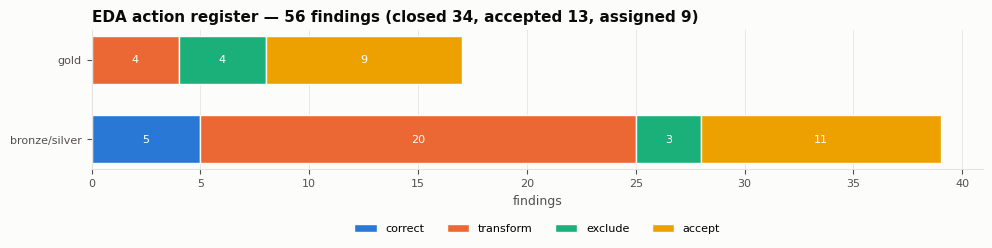

In [33]:
# Chart: action register — findings by layer and action
ct = action_register.groupby(["layer", "action"]).size().unstack(fill_value=0)
order_actions = [a for a in ["correct", "transform", "exclude", "accept", "investigate"] if a in ct.columns]
ct = ct[order_actions]
fig, ax = plt.subplots(figsize=(10, 2.8))
left = np.zeros(len(ct))
palette = SERIES + ["#e87ba4"]
for color, a in zip(palette, order_actions):
    ax.barh(ct.index, ct[a], left=left, color=color, label=a, height=0.6, edgecolor=SURFACE, linewidth=1)
    for yv, (l, v) in enumerate(zip(left, ct[a])):
        if v:
            ax.text(l + v / 2, yv, str(v), ha="center", va="center", fontsize=8, color="white")
    left += ct[a].values
ax.set_xlabel("findings")
ax.grid(axis="y", visible=False)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.32), ncol=len(order_actions))
st = action_register["status"].value_counts().to_dict()
ax.set_title(f"EDA action register — {len(action_register)} findings ({', '.join(f'{k} {v}' for k, v in st.items())})")
fig.tight_layout()
fig.savefig(os.path.join(EDA_CHART_DIR, "15_action_register.png"), dpi=130, bbox_inches="tight")
plt.show()

### Gate 2 check

In [34]:
gate2 = pd.DataFrame([
    dict(criterion="Gold grain and time rules verified",
         evidence="step 13: one row per loan, point-in-time 0 violations, outcome = loan start + 6 months, no label in X; "
                  "step 11 historical replay", status="PASS"),
    dict(criterion="EDA findings resolved or assigned",
         evidence=f"{len(action_register)} findings: " + ", ".join(f"{k} {v}" for k, v in
                                                                  action_register['status'].value_counts().items())
                  + "; none open", status="PASS"),
    dict(criterion="Leakage risks documented",
         evidence=f"leakage watchlist ({len(watchlist)} entries) with actions; 4 strong financial features accepted with "
                  "rationale (AUC < 0.75, known at application)", status="PASS"),
])
gate2.to_csv(os.path.join(EDA_DIR, "gate2_check.csv"), index=False)
gate2.style.hide(axis="index")

criterion,evidence,status
Gold grain and time rules verified,"step 13: one row per loan, point-in-time 0 violations, outcome = loan start + 6 months, no label in X; step 11 historical replay",PASS
EDA findings resolved or assigned,"56 findings: closed 34, accepted 13, assigned 9; none open",PASS
Leakage risks documented,"leakage watchlist (12 entries) with actions; 4 strong financial features accepted with rationale (AUC < 0.75, known at application)",PASS


### Steps 16 and 15 summary

- **16:** no missing periods in any source or cohort; regular clickstream panel; features **stable over time** (PSI well below 0.1 inside training and development vs OOT); monthly default rate within sampling-noise limits (slight upward trend); accepted temporal risks — source freshness, the clickstream coverage break at 2024-07, and the 6-month outcome-window overlap.
- **15:** one action register for all findings — nothing open; items assigned to steps 18 (missing indicators), 23 (constant / duplicate features), 25 (model A vs B) and 27 (re-check strong features).
- **Gate 2 passed.** Next (in `script/mlpipeline.ipynb`): 19 → 23 → 18.